# Cancelamento de reservas de hotel: variáveis do modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Este notebook** parte da base definida no `01_exploratoria.ipynb` (reservas sem depósito, com a limpeza proposta) e decide quais variáveis entram no modelo e de que forma. O modelo e a avaliação ficam no `03_modelo.ipynb`.

Todas as decisões saem do **treino** (chegadas de 2015 e 2016). O teste (2017) só aparece quando a pergunta é se uma relação se mantém no tempo.

## Resumo

*(preenchido ao final da análise)*

- Variáveis que entram, e de que forma: __.
- Variáveis que saem, e por quê: __.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes_logistica import (usar_tabelas_simples, CORES, aplicar_estilo, preparar_base,
                               taxa_por_nivel, grafico_taxa_por_nivel,
                               logito_por_faixa, grafico_logito, v_cramer,
                               comparar_cortes, cortes_por_ganho, desenhar_arvore)

aplicar_estilo()
usar_tabelas_simples()   # todas as tabelas: nomes numa linha, índice como coluna, 4 casas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base do modelo

#### Passos do escopo e da limpeza

O escopo e a limpeza vêm do `01_exploratoria.ipynb`: só reservas sem depósito (seção 5.2) e as remoções propostas na seção 4. A função `preparar_base` aplica os dois e acrescenta o total de noites, o total de hóspedes e a marcação de linhas com gêmea idêntica.

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, passos = preparar_base(hotel)
display(passos)

treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Teste: ', len(teste), f"| cancelamento {teste['is_canceled'].mean():.1%}")

jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']

passo,reservas,saem neste passo
base inteira,119390,
sem depósito (escopo),104641,14749
children preenchido,104637,4
com hóspede,104457,180
diária entre 0 e 1.000,104456,1
com pelo menos uma noite,103811,645


Treino: 67455 | cancelamento 26.8%
Teste:  36356 | cancelamento 31.9%


**Leitura.**

- **Ficam 103.811 reservas.** O escopo tira 14.749 com depósito. As remoções tiram mais 830: 4 sem `children`, 180 sem hóspede, a diária negativa e 645 com zero noites. A diária de 5.400 já tinha saído com o escopo (é Non Refund).
- **Treino: 67.455 reservas, 26,8% de cancelamento. Teste: 36.356, 31,9%.**
- As remoções seguem a proposta do notebook 01, seção 4.

## 2. Univariada

**Perguntas:** como cada candidata se distribui? Há variáveis quase constantes, caudas longas ou categorias pequenas demais para estimar? A distribuição muda entre treino e teste?

As distribuições são descritas no **treino**; o teste só entra na comparação do fim da seção.

### 2.1 Numéricas

#### Resumo

Parcela de zeros e percentis de cada variável.

In [3]:
numericas = ['lead_time', 'adr', 'noites', 'stays_in_weekend_nights', 'stays_in_week_nights',
             'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
             'days_in_waiting_list', 'total_of_special_requests']

def resumo_numerica(s):
    return pd.Series({'pct_zero': (s == 0).mean(), 'p25': s.quantile(.25), 'mediana': s.median(),
                      'p75': s.quantile(.75), 'p95': s.quantile(.95), 'p99': s.quantile(.99), 'max': s.max()})

treino[numericas].apply(resumo_numerica).T.round(4).rename_axis('variavel')

variavel,pct_zero,p25,mediana,p75,p95,p99,max
lead_time,0.0632,12,51,125,272,351,709
adr,0.0130,66.4900,90,120,185,240,508
noites,0,2,3,4,7,14,69
stays_in_weekend_nights,0.4229,0,1,2,2,4,19
stays_in_week_nights,0.0628,1,2,3,5,10,50
adults,0.0024,2,2,2,3,3,55
children,0.9258,0,0,0,1,2,10
babies,0.9903,0,0,0,0,0,10
previous_cancellations,0.9622,0,0,0,0,1,24
previous_bookings_not_canceled,0.9682,0,0,0,0,3,58


**Leitura.**

- **Cinco contagens são quase sempre zero:** `babies` (99,0%), `days_in_waiting_list` (97,7%), `previous_bookings_not_canceled` (96,8%), `previous_cancellations` (96,2%) e `children` (92,6%). Como número, o pouco que não é zero vira cauda (até 58 reservas anteriores mantidas). Se entrarem, entram como sim ou não. `babies` sozinho quase não varia; a bivariada (seção 3.4) mostra se dá para juntar com `children`.
- **`total_of_special_requests`:** 56,3% sem pedido. Candidata a "fez pedido × não fez".
- **`adults`:** o p25 e o p75 são 2, e o máximo é 55. Como número, a cauda pesa mais que o comum. Candidata a "sozinho × acompanhado".

#### Antecedência

Histograma no treino. O gráfico vai até o percentil 99 (351 dias): o 1% de reservas com antecedência maior, até o máximo de 709 dias, fica de fora para não achatar o desenho, e aparece no resumo acima (colunas `p99` e `max`).

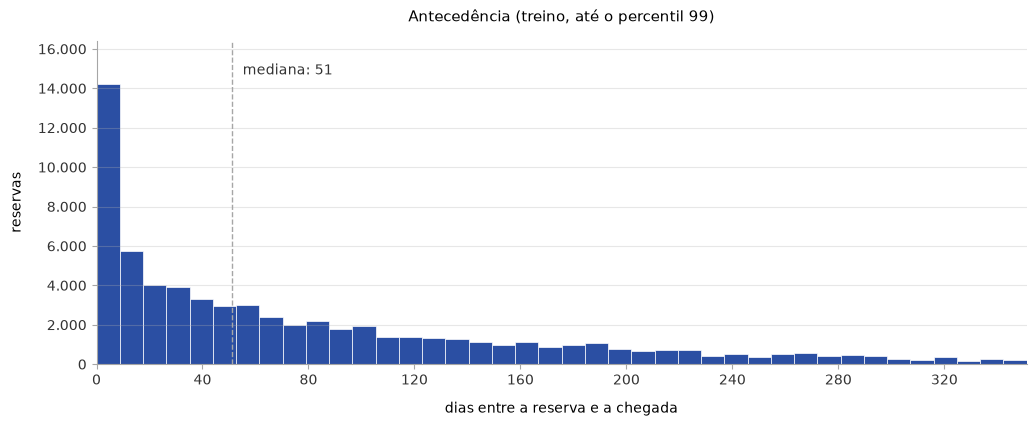

In [4]:
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

milhar = FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))   # 14.000, no padrão brasileiro

# a cauda acima do percentil 99 fica fora do gráfico (está na tabela acima)
def histograma(coluna, titulo, rotulo):
    s = treino[coluna]
    limite = s.quantile(0.99)
    bins = np.arange(s.min(), limite + 2) - 0.5 if coluna == 'noites' else 40
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.hist(s[s <= limite], bins=bins, color=CORES['principal'], edgecolor='white', linewidth=0.5)
    ax.axvline(s.median(), color=CORES['referencia'], linestyle='--', linewidth=1)
    # rótulo ao lado do topo da linha da mediana, numa folga acima da barra mais alta
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.annotate(f'mediana: {s.median():.0f}', xy=(s.median(), 0.93), xycoords=ax.get_xaxis_transform(),
                xytext=(8, 0), textcoords='offset points',   # 8 pontos à direita da linha
                fontsize=10, color='#333333', ha='left', va='top',
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_title(f'{titulo} (treino, até o percentil 99)')
    ax.set_xlabel(rotulo)
    ax.set_ylabel('reservas')
    if coluna == 'noites':
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.set_xlim(s.min() - 0.5, limite + 0.5)   # o eixo y encosta na primeira barra, centrada no menor valor
    else:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlim(0, limite)            # sem folga antes do 0: os eixos se encontram no 0
    ax.yaxis.set_major_formatter(milhar)
    plt.show()


histograma('lead_time', 'Antecedência', 'dias entre a reserva e a chegada')

**Leitura.**

- **`lead_time` tem cauda longa.** Mediana de 51 dias, mas o percentil 99 é 351 e o máximo, 709. 6,3% das reservas são para o próprio dia. Uma reta no logito dificilmente cobre de 0 a 709 dias: confirma a ideia das faixas, a conferir na bivariada.

#### Diária

Histograma no treino. O gráfico vai até o percentil 99 (240 €): o 1% de reservas com diária maior, até o máximo de 508 €, fica de fora para não achatar o desenho, e aparece no resumo acima.

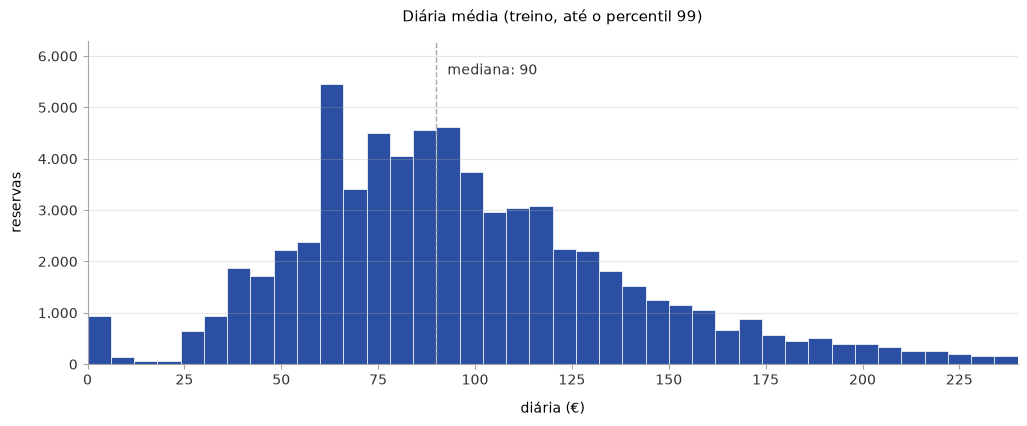

In [5]:
histograma('adr', 'Diária média', 'diária (€)')

**Leitura.**

- **`adr` concentra-se entre 66 e 120** (p25 e p75), com mediana de 90, percentil 99 de 240 e máximo de 508. 1,3% das reservas têm diária zero, que aparece como pico à esquerda no gráfico.

#### Noites

Uma barra por número de noites, no treino. O gráfico vai até o percentil 99 (14 noites): o 1% de reservas mais longas, até o máximo de 69 noites, fica de fora para não achatar o desenho, e aparece no resumo acima.

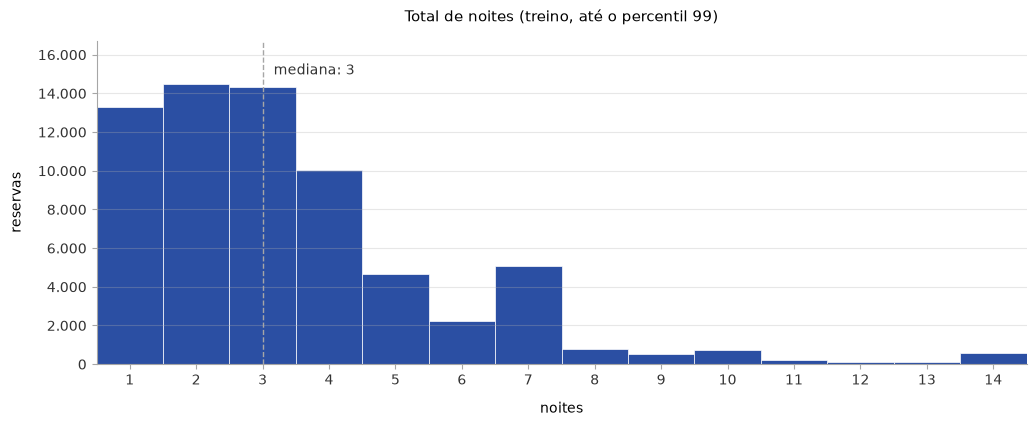

In [6]:
histograma('noites', 'Total de noites', 'noites')

**Leitura.**

- **`noites`: metade das reservas fica de 2 a 4 noites** (p25 e p75), com mediana de 3 e percentil 99 de 14. O pico em 7 é a semana fechada. Faixas de 1, 2–3, 4–7 e mais de 7 noites acompanham esse desenho.

### 2.2 Categóricas

#### Frequências

No treino, marcando as que ficam abaixo de 1%.

In [7]:
categoricas = ['hotel', 'market_segment', 'distribution_channel', 'customer_type', 'meal',
               'reserved_room_type', 'is_repeated_guest']

frequencias = pd.concat({
    c: treino[c].value_counts().rename('reservas').to_frame().assign(pct=lambda t: t['reservas'] / t['reservas'].sum())
    for c in categoricas
})
frequencias.index.names = ['variavel', 'nivel']
frequencias['abaixo_de_1pct'] = frequencias['pct'] < 0.01
frequencias.round(4)

variavel,nivel,reservas,pct,abaixo_de_1pct
hotel,City Hotel,42437,0.6291,False
hotel,Resort Hotel,25018,0.3709,False
market_segment,Online TA,33496,0.4966,False
market_segment,Offline TA/TO,14545,0.2156,False
market_segment,Direct,7848,0.1163,False
market_segment,Groups,7401,0.1097,False
market_segment,Corporate,3531,0.0523,False
market_segment,Complementary,509,0.0075,True
market_segment,Aviation,125,0.0019,True
distribution_channel,TA/TO,53910,0.7992,False


**Leitura.**

- **Categorias abaixo de 1% do treino:**
  - `market_segment`: Complementary (0,8%) e Aviation (0,2%). Juntam em "Outros";
  - `customer_type`: Group (344 reservas, 0,5%). Precisa juntar com outra categoria; a bivariada mostra com qual ela se parece;
  - `meal`: Undefined (642, 0,95%) e FB (408, 0,6%). Undefined fica separado ou junta com SC (notebook 01, seção 4.3); FB pode juntar com HB em "com pensão";
  - `reserved_room_type`: C, H e L (L tem 6 reservas). A variável tende a sair: o código do quarto não significa nada para o público;
  - `distribution_channel`: GDS (0,15%) e uma reserva Undefined. A variável tende a sair por repetir o segmento.
- **Referências naturais (a categoria mais frequente):** City Hotel (62,9%), Online TA (49,7%), Transient (68,9%), BB (78,2%).
- **`is_repeated_guest`:** 3,1% de hóspedes que voltam. Pequeno, mas são 2.110 reservas: dá para estimar.

#### Mês de chegada

Quantas reservas o treino tem em cada mês, em cada ano.

In [8]:
# meses: volume por mês de chegada no treino (2015 só tem julho a dezembro)
meses = ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December']
pd.crosstab(pd.Categorical(treino['arrival_date_month'], meses), treino['arrival_date_year'], margins=True)

row_0,2015,2016,All
January,0,2023,2023
February,0,3354,3354
March,0,4192,4192
April,0,4453,4453
May,0,4683,4683
June,0,4285,4285
July,2524,4256,6780
August,3279,4771,8050
September,3894,4624,8518
October,3833,5363,9196


**Leitura.**

- **O treino não pesa os meses por igual.** 2015 só tem julho a dezembro, então esses meses aparecem em dois anos e janeiro a junho, só em 2016. O efeito de janeiro a junho é estimado com um ano só.

### 2.3 Treino × teste

#### Medianas

Também só de janeiro a agosto nos dois anos, para tirar o efeito da época do ano.

In [9]:
# a distribuição das candidatas muda em 2017? (o teste só tem janeiro a agosto)
comparacao_num = pd.DataFrame({
    'mediana_treino': treino[['lead_time', 'adr', 'noites']].median(),
    'mediana_teste': teste[['lead_time', 'adr', 'noites']].median(),
}).rename_axis('variavel')
display(comparacao_num)

# mesmos meses (janeiro a agosto) para tirar o efeito da época do ano na diária e na antecedência
treino_jan_ago = treino[treino['arrival_date_month'].isin(jan_a_ago) & (treino['arrival_date_year'] == 2016)]
display(pd.DataFrame({
    'mediana_2016_jan_ago': treino_jan_ago[['lead_time', 'adr', 'noites']].median(),
    'mediana_2017_jan_ago': teste[['lead_time', 'adr', 'noites']].median(),
}).rename_axis('variavel'))

variavel,mediana_treino,mediana_teste
lead_time,51,73
adr,90,108
noites,3,3


variavel,mediana_2016_jan_ago,mediana_2017_jan_ago
lead_time,55,73
adr,95,108
noites,3,3


**Leitura.**

- **2017 reserva com mais antecedência e paga mais caro.** Nos mesmos meses (janeiro a agosto), a antecedência mediana sobe de 55 para 73 dias, e a diária mediana, de 95 para 108. O total de noites não muda (3).

#### Composição

Parcela de cada hotel, segmento e tipo de cliente nos dois períodos, e a diferença em pontos percentuais.

In [10]:
composicao = pd.concat({
    c: pd.DataFrame({'treino': treino[c].value_counts(normalize=True),
                     'teste': teste[c].value_counts(normalize=True)})
    for c in ['hotel', 'market_segment', 'customer_type']
}).fillna(0)
composicao['diferenca_pp'] = (composicao['teste'] - composicao['treino']) * 100
composicao.round(4)

variavel,nivel,treino,teste,diferenca_pp
hotel,City Hotel,0.6291,0.6483,1.9195
hotel,Resort Hotel,0.3709,0.3517,-1.9195
market_segment,Aviation,0.0019,0.0029,0.1063
market_segment,Complementary,0.0075,0.0057,-0.1880
market_segment,Corporate,0.0523,0.0375,-1.4883
market_segment,Direct,0.1163,0.1258,0.9495
market_segment,Groups,0.1097,0.0840,-2.5687
market_segment,Offline TA/TO,0.2156,0.1236,-9.2014
market_segment,Online TA,0.4966,0.6205,12.3907
customer_type,Transient,0.6892,0.8119,12.2703


**Leitura.**

- **O mix muda bastante:**
  - a agência online passa de 49,7% para 62,0% das reservas (+12,4 pontos), e a operadora tradicional cai 9,2 pontos;
  - o cliente avulso (Transient) passa de 68,9% para 81,2% (+12,3 pontos), e o avulso ligado a outra reserva (Transient-Party) cai 9,9 pontos.
- **O que isso muda:**
  - se a bivariada mostrar que a agência online e a antecedência longa cancelam mais, parte da alta de 2017 vem da composição. Essa parte o modelo capta, porque as variáveis estão nele; o resto aparece na calibração;
  - a diária sobe em 2017 também por preço. Se `adr` entrar como número, a mesma diária quer dizer coisas diferentes em cada ano. A conferir na bivariada se a relação entre a diária e o cancelamento é a mesma no treino e no teste.

## 3. Bivariada

**Pergunta:** como cada candidata se relaciona com o cancelamento, e em que forma ela entra no modelo?

Tudo no **treino** (2015 e 2016, no escopo). O teste só aparece quando a pergunta é se a relação se mantém em 2017.

Na regressão logística, uma variável numérica tem efeito de reta no logito. O gráfico abaixo mostra o logito empírico de cada faixa contra o valor típico da faixa (a mediana): se os pontos caem numa reta, a variável entra como número; se não, vira faixas ou binária. Contínuas são cortadas em decis; contagens, por valor.

Antecedência, noites e diária não são lineares no logito: entram em faixas (seções 3.1 a 3.3). Os cortes da antecedência e das noites saem da árvore de decisão; os da diária ficam para a seção 4. As contagens que quase sempre valem zero ou que mudam num degrau só entram como sim ou não, ou saem (seção 3.4). As categóricas estão na seção 3.5, e a comparação entre treino e teste, na 3.6.


### 3.1 Antecedência

#### Logito de p por decil

As reservas são divididas em 10 grupos com o mesmo número de reservas, pela antecedência. Cada ponto é o logito da taxa de cancelamento do grupo, na mediana dos dias. Se os pontos formarem uma reta, a antecedência entra como número.

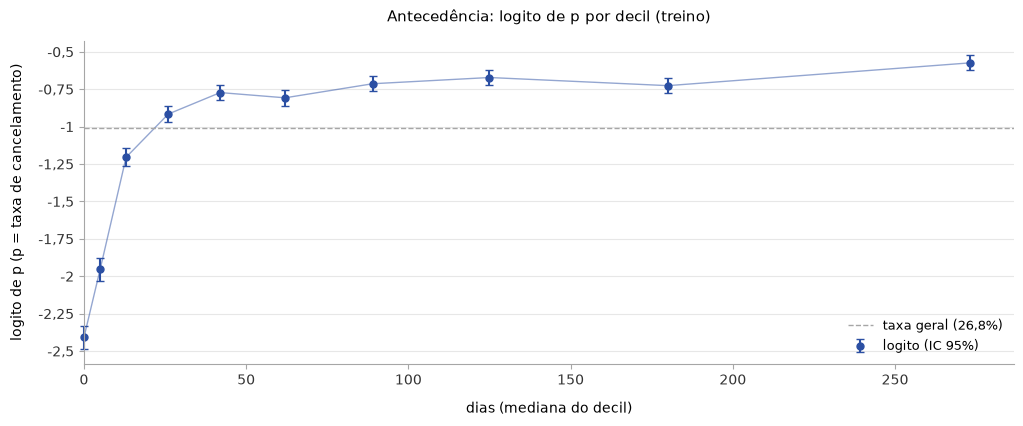

decil,limites,n,taxa,logito,mediana
1,"(-0.001, 2.0]",8057,0.0824,-2.4093,0.0
2,"(2.0, 8.0]",6153,0.1242,-1.9530,5.0
3,"(8.0, 18.0]",6275,0.2306,-1.2047,13.0
4,"(18.0, 34.0]",6904,0.2858,-0.9158,26.0
5,"(34.0, 51.0]",6451,0.3159,-0.7725,42.0
6,"(51.0, 74.0]",6793,0.3084,-0.8075,62.0
7,"(74.0, 104.0]",6587,0.3288,-0.7134,89.0
8,"(104.0, 150.0]",6765,0.3381,-0.6718,125.0
9,"(150.0, 215.0]",6739,0.3260,-0.7262,180.0
10,"(215.0, 709.0]",6731,0.3603,-0.5741,273.0


In [11]:
taxa_treino = treino['is_canceled'].mean()
colunas = ['decil', 'n', 'taxa', 'logito', 'mediana']

def logito_decis(coluna, titulo, rotulo):
    tabela = logito_por_faixa(treino, coluna)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    grafico_logito(tabela, titulo=titulo, rotulo_x=rotulo, taxa_geral=taxa_treino, ax=ax)
    plt.show()
    # decil primeiro e todos os nomes na mesma linha: o índice fica escondido na exibição
    tabela = tabela[colunas].rename_axis('limites').reset_index()
    tabela = tabela[['decil', 'limites', 'n', 'taxa', 'logito', 'mediana']]
    return (tabela.style.hide(axis='index')
                 .format({'taxa': '{:.4f}', 'logito': '{:.4f}', 'mediana': '{:.1f}'}))   # mediana em dias ou euros

logito_decis('lead_time', 'Antecedência: logito de p por decil (treino)',
             'dias (mediana do decil)')

**Leitura.**

- **A antecedência não é linear no logito.** O cancelamento sobe rápido até um mês, de 8,2% (até 2 dias) para 28,6% (19 a 34 dias), e depois quase para: entre 30,8% e 36,0% de 35 a 709 dias. Uma reta não cobre os dois trechos. **Entra em faixas.**

#### Onde cortar: árvore de decisão

A antecedência entra em faixas. Os cortes saem de uma **árvore de decisão com ganho de informação**, usando só a antecedência. O mesmo método vale para as noites, mais abaixo:

1. **A árvore escolhe um corte por vez.** Ela testa todos os cortes possíveis (0 dias, 1 dia, 2 dias...) e fica com o que dá o **maior ganho de informação**: a maior queda na entropia do cancelamento, ou seja, o corte que deixa os grupos menos misturados entre quem cancela e quem vem. Depois, faz o mesmo dentro de cada pedaço.
2. **Regras de parada:**
   - cada faixa precisa ter pelo menos **0,5% do treino** (cerca de 340 reservas), o bastante para estimar a taxa;
   - a árvore para quando o próximo corte traz **menos de 0,0005 de ganho**. Os primeiros cortes trazem ganhos grandes; a partir de certo ponto, os ganhos ficam pequenos e os cortes passam a separar diferenças sem importância.
O desenho mostra a árvore que essas regras produzem: cada pergunta com a parcela das reservas, a taxa de cancelamento e o ganho do corte, e as faixas embaixo. A linha abaixo do desenho mostra por que a árvore parou.

3. **Cada corte é examinado:** a taxa de cada faixa, a ordem e a estabilidade no teste (2017). Um corte que inverte a ordem e pode vir de outra variável é conferido com essa variável no modelo (seção 4).
4. **Comparação:** pelo AIC e pelo BIC, contra a variável como número, o logaritmo, a proposta inicial de faixas e versões com cortes arredondados.

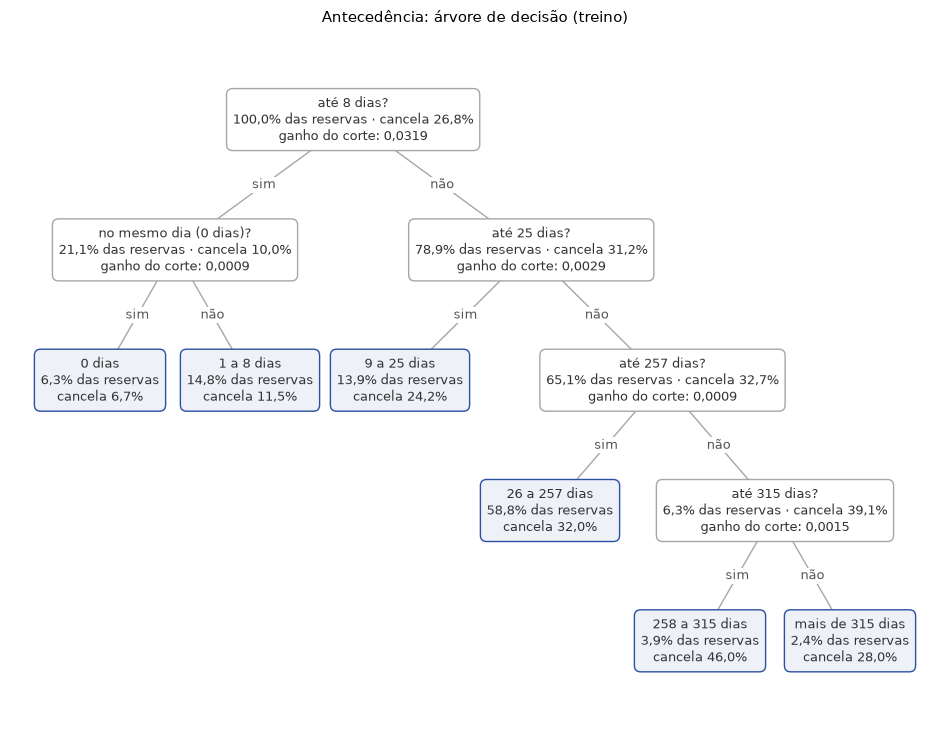

A árvore para em 6 faixas: o próximo corte (251 dias) teria ganho de 0,0004, abaixo do mínimo de 0,0005.


In [12]:
# antecedência: a árvore que as regras de parada produzem (treino)
passos_lead = cortes_por_ganho(treino, 'lead_time')
n_faixas_lead = int((passos_lead['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'lead_time', n_faixas=n_faixas_lead, unidade='dias',
                titulo='Antecedência: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_lead[passos_lead['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.4f}".replace('.', ',')
print(f"A árvore para em {n_faixas_lead} faixas: o próximo corte ({parada['corte_novo']} dias) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **O primeiro corte, em 8 dias, traz quase todo o ganho** (0,0319). Ele separa as reservas feitas com até 8 dias de antecedência das feitas com 9 dias ou mais.
- **Depois, a árvore subdivide cada lado.** Até 8 dias, separa o mesmo dia da chegada (0,0009). Acima de 8 dias, corta em 25 dias (0,0029), em 257 (0,0009) e em 315 (0,0015). Esses ganhos são dez vezes menores que o do primeiro.
- **A árvore para em 6 faixas:** o próximo corte, em 251 dias, teria ganho de 0,0004, abaixo do mínimo.
- **O corte em 315 dias quebra a escada:** em todas as outras faixas, quanto maior a antecedência, maior o cancelamento; acima de 315 dias, a taxa cai. Examinado abaixo.
- **Resultado: 6 faixas:** no mesmo dia, 1 a 8, 9 a 25, 26 a 257, 258 a 315 e mais de 315 dias.

#### O corte de 315 dias

Taxa de cancelamento das duas últimas faixas da árvore, no treino e no teste, e quem são essas reservas (segmento e linhas idênticas).

In [13]:
# o corte em 315 dias: quem reserva com mais de 315 dias de antecedência?
faixa_cauda = pd.cut(base['lead_time'], [-1, 257, 315, np.inf], labels=['até 257', '258–315', 'mais de 315'])
cauda = base.assign(faixa_cauda=faixa_cauda, periodo=np.where(base['arrival_date_year'] < 2017, 'treino', 'teste'))
cauda = cauda[cauda['faixa_cauda'] != 'até 257']
display(cauda.pivot_table(index='faixa_cauda', columns='periodo', values='is_canceled', aggfunc=['mean', 'size'],
                          observed=True).pipe(lambda t: t.set_axis([f'{a} {b}' for a, b in t.columns], axis=1))
        .rename(columns=lambda c: c.replace('mean', 'taxa').replace('size', 'reservas'))
        [['taxa treino', 'taxa teste', 'reservas treino', 'reservas teste']].round(4))
cauda[cauda['periodo'] == 'treino'].groupby('faixa_cauda', observed=True).agg(
    pct_grupo_ou_operadora=('market_segment', lambda s: s.isin(['Groups', 'Offline TA/TO']).mean()),
    pct_com_linha_identica=('tem_gemea', 'mean'),
).round(4)

faixa_cauda,taxa treino,taxa teste,reservas treino,reservas teste
258–315,0.4596,0.5301,2609,1528
mais de 315,0.2804,0.3626,1619,1470


faixa_cauda,pct_grupo_ou_operadora,pct_com_linha_identica
258–315,0.7558,0.6777
mais de 315,0.9055,0.6720


**Leitura.**

- **Acima de 315 dias, o cancelamento cai em vez de subir:** 28,0% no treino e 36,3% no teste, contra 46,0% e 53,0% de 258 a 315 dias. A diferença se repete em 2017: o corte não é acaso.
- **Essas reservas são quase todas de grupos e operadoras:** 90,5% acima de 315 dias (75,6% de 258 a 315), e 67,2% têm linha idêntica. São os blocos de quartos reservados com quase um ano de antecedência.
- **Por isso, a queda pode ser efeito do segmento**, e não da antecedência. Com a antecedência sozinha no modelo, não dá para separar os dois.
- **O corte fica.** A seção 4 confere se ele continua melhorando o modelo com o segmento junto. Se não melhorar, as duas últimas faixas se juntam em "mais de 257 dias".

#### Comparação das opções de corte

Cada opção vira um modelo só com a antecedência, e as opções são comparadas pelo AIC e pelo BIC: nos dois, quanto menor, melhor, e as colunas `dif_` dão a distância para a melhor opção. Entram a árvore com e sem o corte de 315, uma versão com cortes arredondados, a proposta inicial de faixas, a antecedência como número, o logaritmo e o modelo sem nenhuma variável.

In [14]:
# antecedência: as faixas da árvore comparadas com as outras opções (treino)
opcoes_lead = {
    'árvore: 0 / 1–8 / 9–25 / 26–257 / 258–315 / mais de 315': [-1, 0, 8, 25, 257, 315, np.inf],
    'árvore sem o corte de 315: 0 / 1–8 / 9–25 / 26–257 / mais de 257': [-1, 0, 8, 25, 257, np.inf],
    'arredondada: 0 / 1–7 / 8–30 / 31–270 / mais de 270': [-1, 0, 7, 30, 270, np.inf],
    'proposta inicial: até 7 / 8–30 / 31–90 / 91–180 / mais de 180': [-1, 7, 30, 90, 180, np.inf],
}
comparar_cortes(treino, 'lead_time', opcoes_lead, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'antecedência como número': 'is_canceled ~ lead_time',
    'logaritmo da antecedência': 'is_canceled ~ np.log1p(lead_time)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
árvore: 0 / 1–8 / 9–25 / 26–257 / 258–315 / mais de 315,6,5,74832.4000,0,74887.1000,0,0.0240,"6,7% / 11,5% / 24,2% / 32,0% / 46,0% / 28,0%"
árvore sem o corte de 315: 0 / 1–8 / 9–25 / 26–257 / mais de 257,5,4,74968,135.5000,75013.6000,126.4000,0.0627,"6,7% / 11,5% / 24,2% / 32,0% / 39,1%"
arredondada: 0 / 1–7 / 8–30 / 31–270 / mais de 270,5,4,75068.9000,236.5000,75114.5000,227.4000,0.0521,"6,7% / 11,0% / 25,0% / 32,4% / 37,2%"
proposta inicial: até 7 / 8–30 / 31–90 / 91–180 / mais de 180,5,4,75103.1000,270.7000,75148.7000,261.5000,0.1489,"9,7% / 25,0% / 30,9% / 33,5% / 35,5%"
logaritmo da antecedência,,1,75387.4000,555,75405.6000,518.5000,,
antecedência como número,,1,77129.8000,2297.4000,77148,2260.9000,,
sem nenhuma variável,,0,78375.6000,3543.2000,78384.7000,3497.6000,,


**Leitura.**

- **As faixas vencem a antecedência como número com folga:** o número fica 2.260,9 pontos de BIC atrás da melhor opção, e o logaritmo, 518,5.
- **A árvore com 6 faixas é a melhor opção** pelo AIC e pelo BIC. Sem o corte de 315, perde 126,4 pontos de BIC.
- **Mesmo sem o corte de 315, a árvore ganha das outras opções de 5 faixas:** a versão com cortes arredondados (0, 7, 30 e 270 dias) fica 227,4 pontos atrás da melhor, e a proposta inicial, 261,5. Arredondar os cortes custa caro: 8 e 25 dias separam melhor que 7 e 30.
- **Proposta: as 6 faixas da árvore:** no mesmo dia (0), 1–8, 9–25, 26–257, 258–315 e mais de 315 dias.

#### Faixas finais

Taxa de cancelamento de cada faixa no treino, com o intervalo de confiança, e no teste (2017), para conferir se a ordem se mantém.

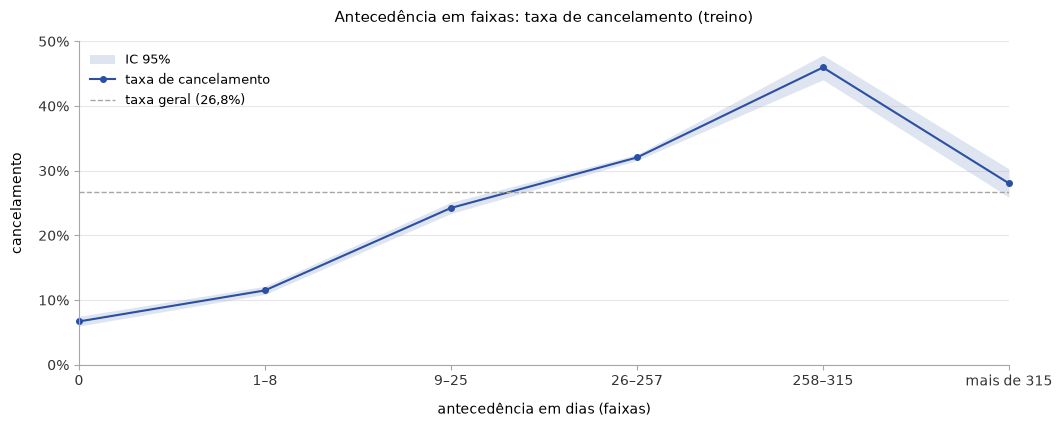

lead_time,n,pct_base,taxa,ic_inf,ic_sup,taxa_teste
0,4260,0.0632,0.0669,0.0598,0.0748,0.0633
1–8,9950,0.1475,0.1149,0.1088,0.1213,0.0999
9–25,9353,0.1387,0.2424,0.2338,0.2512,0.2761
26–257,39664,0.5880,0.3204,0.3158,0.3250,0.3708
258–315,2609,0.0387,0.4596,0.4405,0.4787,0.5301
mais de 315,1619,0.0240,0.2804,0.2591,0.3028,0.3626


In [15]:
# faixas escolhidas: taxa no treino (com intervalo) e no teste, que precisa manter a ordem
def conferir_faixas(variavel, limites, rotulos, titulo, rotulo_x):
    faixa = lambda dados: pd.cut(dados[variavel], limites, labels=rotulos)
    tabela = taxa_por_nivel(treino.assign(faixa=faixa(treino)), 'faixa')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']]
    tabela['taxa_teste'] = teste.groupby(faixa(teste), observed=True)['is_canceled'].mean()
    ax = grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, linha=True, titulo=titulo)
    ax.figure.set_size_inches(12, 4.2)
    ax.set_ylim(0, 0.5)
    ax.set_xlabel(rotulo_x)
    plt.show()
    return tabela.rename_axis(variavel).round(4)

# limites para o pd.cut (cada faixa inclui o limite da direita; o -1 serve para incluir o 0):
#   (-1, 0] = 0 dias | (0, 8] = 1 a 8 | (8, 25] = 9 a 25 | (25, 257] = 26 a 257 | (257, 315] = 258 a 315 | (315, inf) = mais de 315
faixas_lead = [-1, 0, 8, 25, 257, 315, np.inf]
rotulos_lead = ['0', '1–8', '9–25', '26–257', '258–315', 'mais de 315']
conferir_faixas('lead_time', faixas_lead, rotulos_lead,
                'Antecedência em faixas: taxa de cancelamento (treino)',
                'antecedência em dias (faixas)')

**Leitura.**

- **A taxa sobe até 315 dias:** 6,7% no mesmo dia, 11,5% de 1 a 8 dias, 24,2% de 9 a 25, 32,0% de 26 a 257 e 46,0% de 258 a 315. Acima de 315 dias, cai para 28,0%. Os intervalos de faixas vizinhas não se tocam.
- **A ordem se mantém no teste:** 6,3%, 10,0%, 27,6%, 37,1%, 53,0% e 36,3%. As faixas a partir de 9 dias cancelam mais em 2017; a seção 3.6 olha essa mudança.
- **As duas últimas faixas são pequenas:** 3,9% e 2,4% do treino (2.609 e 1.619 reservas), o bastante para estimar a taxa. **Referência: 26–257 dias**, a maior (58,8% do treino).
- **Para a apresentação:** "no mesmo dia", "até uma semana", "até três semanas", "até oito meses", "de oito a dez meses" e "mais de dez meses".

### 3.2 Noites

#### Logito de p por valor

Um ponto por número de noites; o último junta a cauda. Se os pontos formarem uma reta, as noites entram como número.

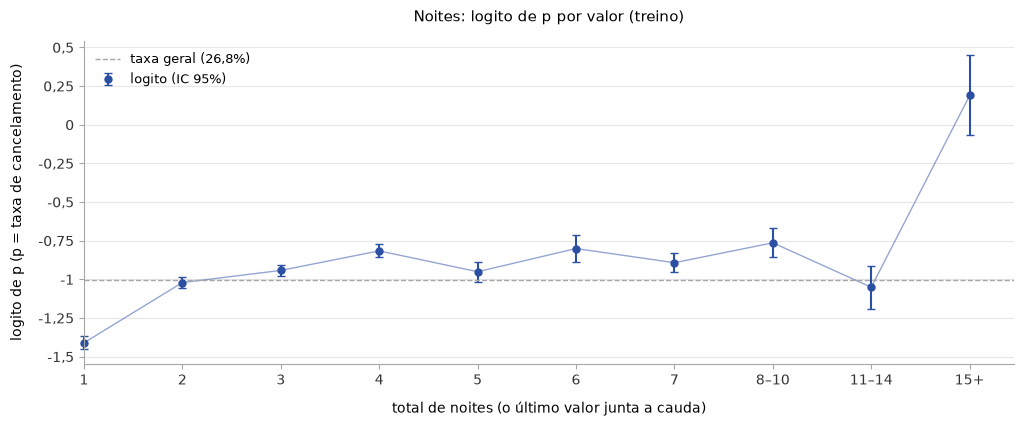

noites,n,taxa,ic_inf,ic_sup
1,13318,0.1961,0.1895,0.2030
2,14477,0.2649,0.2578,0.2722
3,14350,0.2804,0.2731,0.2878
4,10025,0.3066,0.2977,0.3157
5,4657,0.2787,0.2660,0.2918
6,2250,0.3098,0.2910,0.3292
7,5055,0.2906,0.2782,0.3033
8–10,2036,0.3178,0.2979,0.3383
11–14,1055,0.2588,0.2332,0.2860
15+,232,0.5474,0.4831,0.6102


In [16]:
# noites: logito de p por valor (treino); o último valor junta a cauda
limites_valor_noites = [0, 1, 2, 3, 4, 5, 6, 7, 10, 14, np.inf]
rotulos_valor_noites = ['1', '2', '3', '4', '5', '6', '7', '8–10', '11–14', '15+']
tabela_noites = logito_por_faixa(treino, 'noites', limites=limites_valor_noites)
tabela_noites.index = rotulos_valor_noites

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_noites, titulo='Noites: logito de p por valor (treino)',
               rotulo_x='total de noites (o último valor junta a cauda)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_valor_noites)), ax=ax)
ax.set_xticks(range(len(rotulos_valor_noites)), rotulos_valor_noites)
plt.show()

tabela_noites[['n', 'taxa', 'ic_inf', 'ic_sup']].rename_axis('noites').round(4)

**Leitura.**

- **Uma noite cancela bem menos:** 19,6% com uma noite; de 2 a 14 noites, a taxa fica entre 25,9% e 31,8%. 15 noites ou mais cancelam 54,7%, mas são só 232. Não é linear no logito: **entra em faixas**.

#### Onde cortar: árvore de decisão

Mesmo método da antecedência: a árvore de decisão com ganho de informação escolhe os cortes, com as mesmas regras de parada (pelo menos 0,5% do treino por faixa e ganho mínimo de 0,0005 por corte), e as faixas são comparadas pelo AIC e pelo BIC. As reservas com zero noites já saíram da base (notebook 01, seção 4.4).

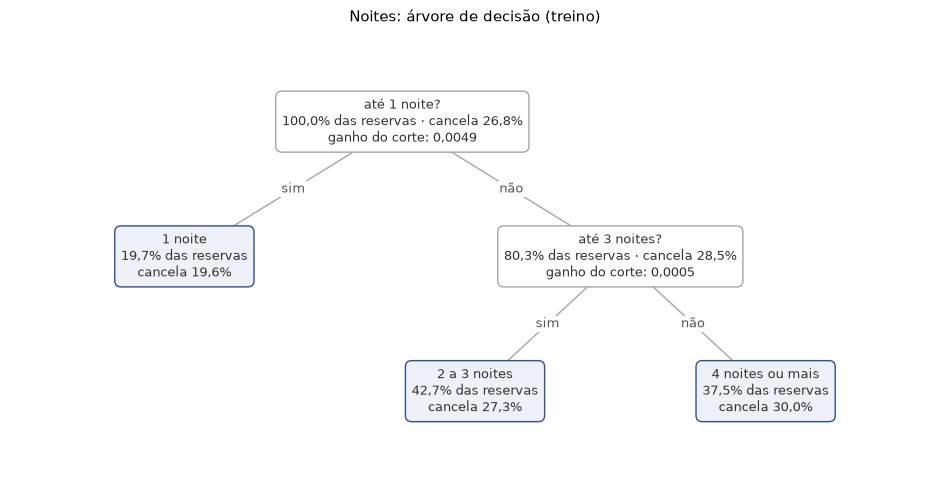

A árvore para em 3 faixas: o próximo corte (2 noites) teria ganho de 0,0001, abaixo do mínimo de 0,0005.


In [17]:
# noites: a árvore que as regras de parada produzem (treino), com o mesmo método da antecedência
passos_noites = cortes_por_ganho(treino, 'noites')
n_faixas_noites = int((passos_noites['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'noites', n_faixas=n_faixas_noites, unidade='noites', ultima='ou mais',
                titulo='Noites: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_noites[passos_noites['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.4f}".replace('.', ',')
print(f"A árvore para em {n_faixas_noites} faixas: o próximo corte ({parada['corte_novo']} noites) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **O primeiro corte separa 1 noite das demais** (ganho de 0,0049).
- **Depois, acima de 1 noite, a árvore separa 2–3 de 4 ou mais** (0,0005).
- **A árvore para em 3 faixas:** o próximo corte, entre 2 e 3 noites, teria ganho de 0,0001, abaixo do mínimo.
- **Resultado: 3 faixas:** 1, 2–3 e 4 ou mais noites.

#### Comparação das opções de corte

Como na antecedência: a árvore, a proposta inicial de faixas, as noites como número, o logaritmo e o modelo sem nenhuma variável, comparados pelo AIC e pelo BIC.

In [18]:
# noites: as faixas da árvore comparadas com as outras opções (treino)
opcoes_noites = {
    'árvore: 1 / 2–3 / 4 ou mais': [0, 1, 3, np.inf],
    'proposta inicial: 1 / 2–3 / 4–7 / mais de 7': [0, 1, 3, 7, np.inf],
}
comparar_cortes(treino, 'noites', opcoes_noites, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'noites como número': 'is_canceled ~ noites',
    'logaritmo das noites': 'is_canceled ~ np.log1p(noites)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
proposta inicial: 1 / 2–3 / 4–7 / mais de 7,4,3,77873.3000,0,77909.8000,6.8000,0.0493,"19,6% / 27,3% / 29,7% / 31,5%"
árvore: 1 / 2–3 / 4 ou mais,3,2,77875.6000,2.3000,77902.9000,0,0.1974,"19,6% / 27,3% / 30,0%"
logaritmo das noites,,1,77999,125.7000,78017.3000,114.3000,,
noites como número,,1,78135.9000,262.6000,78154.1000,251.2000,,
sem nenhuma variável,,0,78375.6000,502.3000,78384.7000,481.8000,,


**Leitura.**

- **A árvore (1 / 2–3 / 4 ou mais) e a proposta inicial (1 / 2–3 / 4–7 / mais de 7) quase empatam.** Pelo AIC, a proposta inicial fica 2,3 pontos à frente; pelo BIC, a árvore fica 6,8 pontos à frente. A separação extra entre 4–7 e mais de 7 noites não se sustenta pelo BIC, e fica a versão mais simples.
- **Noites como número fica 251,2 pontos de BIC atrás**, e o logaritmo, 114,3.
- **Proposta: as 3 faixas da árvore:** 1, 2–3 e 4 ou mais noites.

#### Faixas finais

Taxa de cada faixa no treino, com o intervalo de confiança, e no teste.

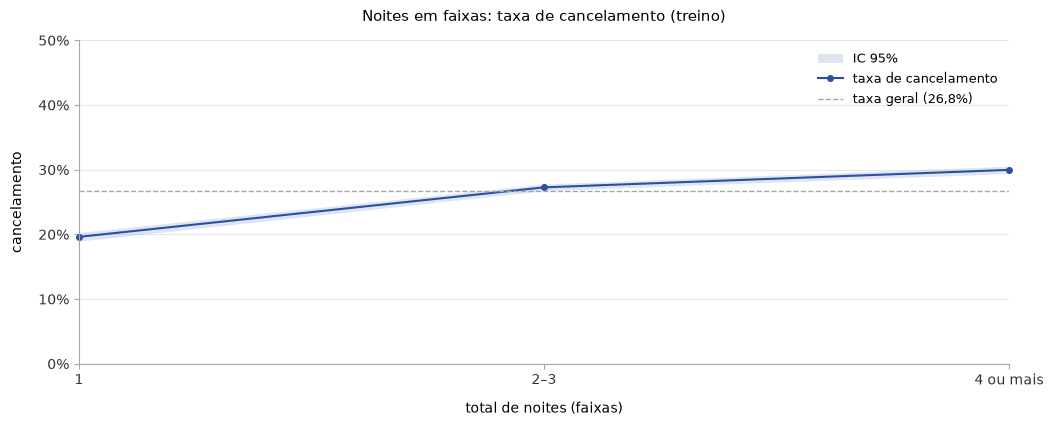

noites,n,pct_base,taxa,ic_inf,ic_sup,taxa_teste
1,13318,0.1974,0.1961,0.1895,0.2030,0.2091
2–3,28827,0.4274,0.2726,0.2675,0.2778,0.3190
4 ou mais,25310,0.3752,0.2997,0.2941,0.3054,0.3638


In [19]:
# limites para o pd.cut (cada faixa inclui o limite da direita):
#   (0, 1] = 1 noite | (1, 3] = 2 a 3 | (3, inf) = 4 ou mais
faixas_noites = [0, 1, 3, np.inf]
rotulos_noites = ['1', '2–3', '4 ou mais']
conferir_faixas('noites', faixas_noites, rotulos_noites,
                'Noites em faixas: taxa de cancelamento (treino)',
                'total de noites (faixas)')

**Leitura.**

- **A taxa sobe nas três faixas:** 19,6% com 1 noite, 27,3% com 2–3 e 30,0% com 4 ou mais. Os intervalos de faixas vizinhas não se tocam.
- **A ordem se mantém no teste:** 20,9%, 31,9% e 36,4%.
- **Referência: 2–3 noites**, a maior (42,7% do treino).

### 3.3 Diária

#### Logito de p por decil

Como na antecedência, com a diária. Abaixo, o primeiro decil separado entre diária zero e diária positiva.

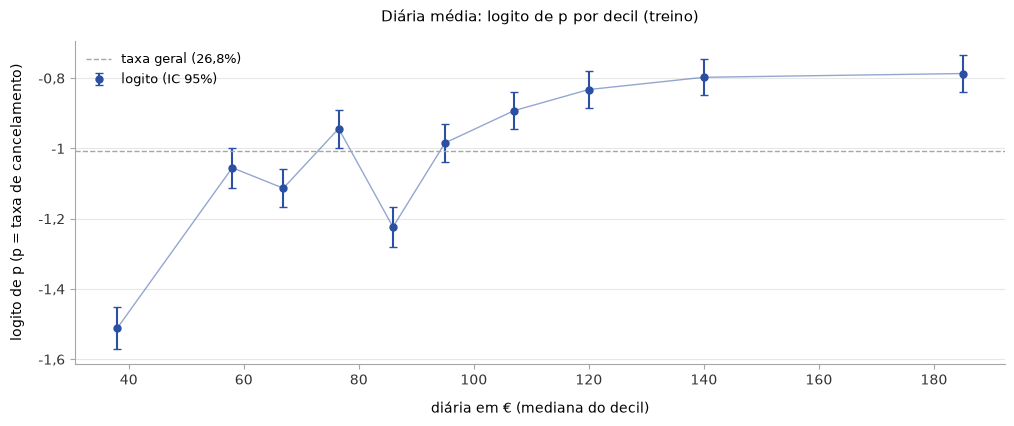

decil,limites,n,taxa,logito,mediana
1,"(-0.001, 48.0]",7140,0.1807,-1.5115,38.0
2,"(48.0, 62.538]",6351,0.2582,-1.0550,58.0
3,"(62.538, 72.25]",6929,0.2472,-1.1133,66.9
4,"(72.25, 80.75]",6583,0.2801,-0.9437,76.5
5,"(80.75, 90.0]",6776,0.2273,-1.2235,85.9
6,"(90.0, 100.0]",6724,0.2720,-0.9843,95.0
7,"(100.0, 113.6]",6725,0.2906,-0.8925,107.0
8,"(113.6, 129.6]",6747,0.3031,-0.8325,120.0
9,"(129.6, 157.0]",6760,0.3105,-0.7976,140.0
10,"(157.0, 508.0]",6720,0.3128,-0.7869,185.0


faixa_adr,n,taxa,ic_inf,ic_sup
zero,877,0.1460,0.1241,0.1709
até 47,5410,0.1713,0.1615,0.1816
acima de 47,61168,0.2779,0.2744,0.2815


In [20]:
display(logito_decis('adr', 'Diária média: logito de p por decil (treino)',
                     'diária em € (mediana do decil)'))

# o primeiro decil da diária inclui as diárias zero (notebook 01, seção 4.3)
taxa_por_nivel(treino.assign(faixa_adr=pd.cut(treino['adr'], [-1, 0, 47, np.inf], labels=['zero', 'até 47', 'acima de 47'])),
               'faixa_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

**Leitura.**

- **A diária também não é linear.** O primeiro decil (até 48) cancela 18,1%, puxado pelas diárias zero (14,6%). Entre 48 e 100, a taxa oscila de 22,7% a 28,0%, sem escada; acima de 114, fica perto de 31%. **Vira faixas.** Os cortes ficam para depois de controlar hotel e temporada: a diária muda com os dois, e parte desse desenho pode vir deles.

### 3.4 Variáveis sim ou não

Contagens que quase sempre valem zero ou que mudam num degrau só: entram como sim ou não, ou saem.

#### Hóspedes

Logito de p por valor de adultos, crianças, bebês e pedidos especiais.

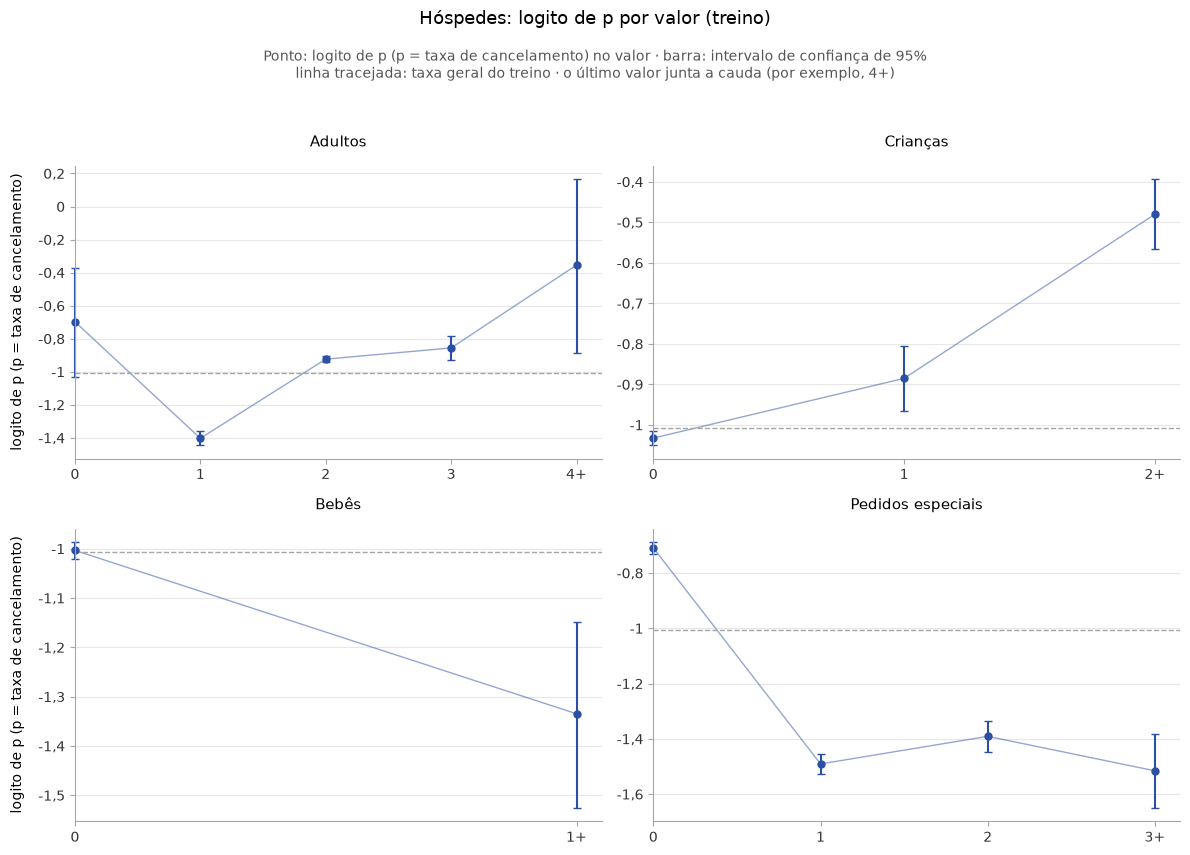

variavel,nivel,n,taxa,ic_inf,ic_sup
adults,0,160,0.3312,0.2630,0.4074
adults,1,13555,0.1973,0.1907,0.2041
adults,2,50152,0.2842,0.2802,0.2881
adults,3,3532,0.2981,0.2833,0.3134
adults,4+,56,0.4107,0.2917,0.5412
children,0,62449,0.2626,0.2592,0.2661
children,1,2842,0.2920,0.2756,0.3090
children,2+,2164,0.3822,0.3619,0.4028
babies,0,66801,0.2683,0.2649,0.2716
babies,1+,654,0.2080,0.1786,0.2407


In [21]:
# contagens: o último nível junta a cauda (por exemplo, 4+ = 4 ou mais adultos)
grupos = {
    'Hóspedes': [
        ('adults', [-1, 0, 1, 2, 3, np.inf], ['0', '1', '2', '3', '4+'], 'Adultos'),
        ('children', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Crianças'),
        ('babies', [-1, 0, np.inf], ['0', '1+'], 'Bebês'),
        ('total_of_special_requests', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Pedidos especiais'),
    ],
    'Histórico do cliente': [
        ('previous_bookings_not_canceled', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Reservas anteriores mantidas'),
        ('days_in_waiting_list', [-1, 0, np.inf], ['0', '1+'], 'Dias em lista de espera'),
        ('previous_cancellations', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Cancelamentos anteriores'),
    ],
}

def figura_contagens(tema):
    contagens = grupos[tema]
    tabelas = {}
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8.5))
    for ax, (coluna, limites, rotulos, titulo) in zip(eixos.flat, contagens):
        tabelas[coluna] = logito_por_faixa(treino, coluna, limites=limites)
        tabelas[coluna].index = rotulos
        # níveis igualmente espaçados no eixo; a cauda fica no último
        grafico_logito(tabelas[coluna], titulo=titulo, taxa_geral=taxa_treino, posicao=range(len(rotulos)), ax=ax)
        ax.set_xticks(range(len(rotulos)), rotulos)
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in list(eixos.flat)[len(contagens):]:
        ax.set_visible(False)      # painel sobrando na grade
    for ax in eixos[:, 0]:
        ax.set_ylabel('logito de p (p = taxa de cancelamento)')
    fig.suptitle(f'{tema}: logito de p por valor (treino)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 0.955, 'Ponto: logito de p (p = taxa de cancelamento) no valor · barra: intervalo de confiança de 95%\n'
             'linha tracejada: taxa geral do treino · o último valor junta a cauda (por exemplo, 4+)',
             ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, 0.91))
    plt.show()
    return pd.concat({c: t[['n', 'taxa', 'ic_inf', 'ic_sup']] for c, t in tabelas.items()}).round(4)


figura_contagens('Hóspedes')

**Leitura.**

- **`adults`: o nível 1 se separa.** Um adulto cancela 19,7%; dois, 28,4%; três, 29,8%, com intervalos que quase se tocam. Os extremos têm poucas reservas e intervalos largos: 0 adulto (160 reservas, 33,1%) e 4 ou mais (56, 41,1%). **Binária: sozinho (1 adulto) × acompanhado** (os demais, incluindo os 160 sem adulto).
- **`children`: escada.** Sem criança, 26,3%; uma, 29,2%; duas ou mais, 38,2%. **Binária, com criança × sem**, ou três níveis se o modelo mostrar que a diferença entre uma e duas compensa.
- **`babies` vai no sentido oposto.** Com bebê, 20,8% (IC de 17,9% a 24,1%), contra 26,8% sem. Juntar com `children` misturaria efeitos contrários. São 654 reservas (1% do treino). **Sai.**
- **`total_of_special_requests`: o que importa é fazer algum pedido.** Sem pedido, 33,0%; com 1, 2 ou 3 ou mais, entre 18,0% e 19,9%. **Binária: fez pedido × não fez**, se o momento do score permitir.

#### Histórico do cliente

Logito de p por valor das reservas anteriores mantidas, dos dias em lista de espera e dos cancelamentos anteriores.

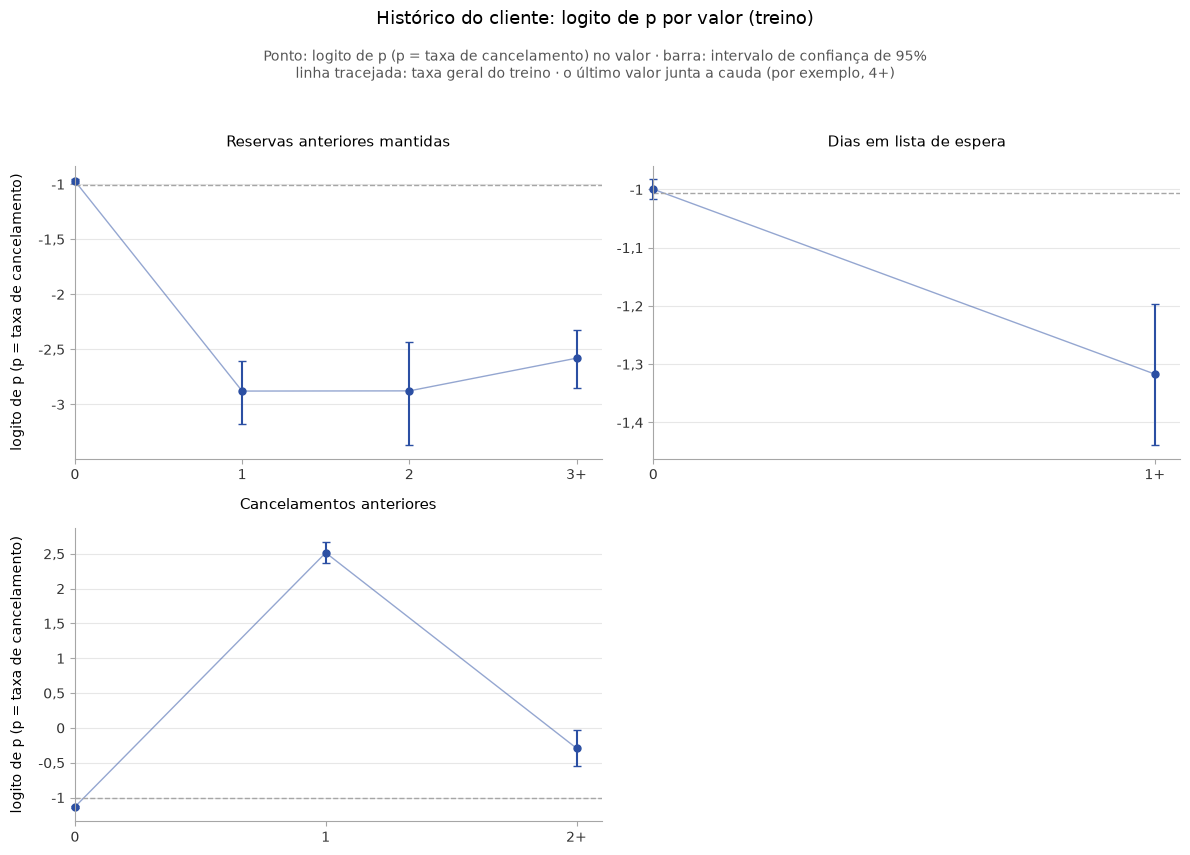

variavel,nivel,n,taxa,ic_inf,ic_sup
previous_bookings_not_canceled,0,65308,0.2745,0.2711,0.2780
previous_bookings_not_canceled,1,929,0.0527,0.0401,0.0690
previous_bookings_not_canceled,2,346,0.0520,0.0332,0.0807
previous_bookings_not_canceled,3+,872,0.0700,0.0548,0.0888
days_in_waiting_list,0,65892,0.2690,0.2656,0.2724
days_in_waiting_list,1+,1563,0.2111,0.1916,0.2321
previous_cancellations,0,64902,0.2436,0.2403,0.2469
previous_cancellations,1,2319,0.9254,0.9140,0.9354
previous_cancellations,2+,234,0.4274,0.3656,0.4914


In [22]:
figura_contagens('Histórico do cliente')

**Leitura.**

- **`previous_bookings_not_canceled`: um degrau.** Nunca veio, 27,5%; já veio uma ou mais vezes, entre 5,2% e 7,0%. **Binária: já veio × nunca veio.**
- **`days_in_waiting_list`:** quem esperou cancela 21,1%, contra 26,9%. São 2,3% das reservas: pouco ganho para uma variável a mais. **Sai.**
- **`previous_cancellations` não segue escada nenhuma:** uma vez, 92,5%; duas ou mais, 42,7%. Investigado abaixo.

#### Cancelamentos anteriores: perfil

Perfil de cada nível: taxa, parcela de 2015, antecedência, linhas idênticas e hóspedes que voltam.

In [23]:
# cancelamentos anteriores: quem são as reservas com exatamente 1?
treino_pc = treino.assign(cancelou_antes=treino['previous_cancellations'].clip(upper=2))
display(treino_pc.groupby('cancelou_antes').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_2015=('arrival_date_year', lambda s: (s == 2015).mean()),
    antecedencia_mediana=('lead_time', 'median'),
    pct_com_gemea=('tem_gemea', 'mean'),
    pct_hospede_repetido=('is_repeated_guest', 'mean'),
).rename(index={2: '2 ou mais'}))

cancelou_antes,reservas,taxa,pct_2015,antecedencia_mediana,pct_com_gemea,pct_hospede_repetido
0,64902,0.2436,0.2500,50,0.2529,0.0230
1,2319,0.9254,0.7986,199,0.6520,0.1962
2 ou mais,234,0.4274,0.2821,8,0.2521,0.7009


**Leitura.**

- **As reservas com exatamente um cancelamento anterior não são clientes que costumam cancelar.** 79,9% são de 2015 (contra 25,0% das reservas sem cancelamento anterior), têm antecedência mediana de 199 dias e 65,2% têm gêmea. É o perfil dos blocos de quartos do notebook 01, seção 4.2, concentrados no início da base.
- **Explicação provável:** em 2015, a contagem parece registrar os outros quartos do mesmo bloco cancelado, e não o histórico do cliente. Não dá para confirmar sem o sistema do hotel.

#### Cancelamentos anteriores: treino × teste

Taxa de cancelamento por número de cancelamentos anteriores, no treino e no teste.

In [24]:
# a relação se mantém em 2017?
pd.DataFrame({
    'taxa_treino': treino.groupby(treino['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'taxa_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'n_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2)).size(),
}).rename(index={2: '2 ou mais'}).round(4)

previous_cancellations,taxa_treino,taxa_teste,n_teste
0,0.2436,0.3198,36080
1,0.9254,0.1762,193
2 ou mais,0.4274,0.1687,83


**Leitura.**

- **Em 2017, a relação se inverte.** No teste, quem tem um cancelamento anterior cancela 17,6%, contra 32,0% de quem não tem. No treino eram 92,5%. Uma variável que muda de sentido entre os períodos ensinaria ao modelo uma regra que não vale no futuro.
- **Proposta: sai.** O histórico do cliente continua representado por "já veio × nunca veio".

### 3.5 Categóricas: força e agrupamentos

#### V de Cramér

O V de Cramér ordena as candidatas pela força da associação com o cancelamento (de 0 a 1). Com muitos níveis, o V tende a sair maior só por isso: a comparação vale melhor entre variáveis com poucos níveis.

In [25]:
treino = treino.assign(
    segmento=treino['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}),
    tem_agencia=treino['agent'].notna(),
    tem_empresa=treino['company'].notna(),
)

candidatas = ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
              'is_repeated_guest', 'arrival_date_month', 'tem_agencia', 'tem_empresa', 'agent', 'company']
pd.DataFrame({
    'niveis': [treino[c].nunique() for c in candidatas],
    'V_cramer': [v_cramer(treino, c) for c in candidatas],
}, index=candidatas).rename_axis('variavel').sort_values('V_cramer', ascending=False).round(4)

variavel,niveis,V_cramer
company,289,0.4050
agent,275,0.2832
segmento,6,0.1950
distribution_channel,5,0.1284
tem_agencia,2,0.1126
tem_empresa,2,0.0875
arrival_date_month,12,0.0812
meal,5,0.0715
hotel,2,0.0688
customer_type,4,0.0491


**Leitura.**

- **Entre as variáveis de poucos níveis, o segmento é a mais forte** (V de 0,195). Depois vêm o canal (0,128), `tem_agencia` (0,113), `tem_empresa` (0,088), o mês (0,081), `meal` (0,072) e o hotel (0,069). Tipo de cliente, tipo de quarto e hóspede que volta ficam abaixo de 0,05.
- **`agent` e `company` têm V alto (0,283 e 0,405), mas com 275 e 289 códigos.** Boa parte disso vem do número de níveis. Investigadas abaixo.

#### Como a reserva chega

Hotel, segmento, canal e tipo de cliente, todos na mesma escala; os números estão na tabela abaixo das figuras.

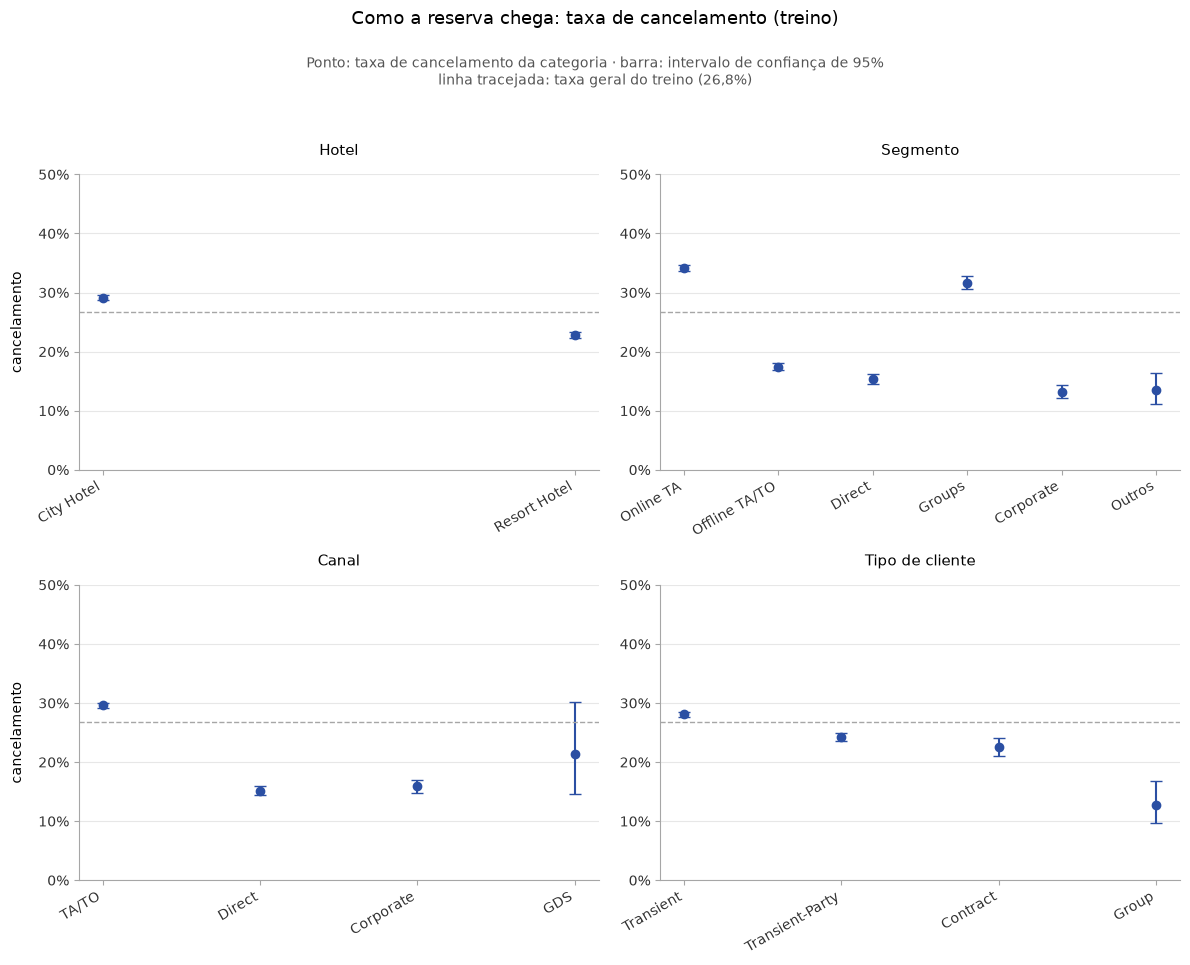

variavel,nivel,n,taxa,ic_inf,ic_sup
hotel,City Hotel,42437,0.2911,0.2868,0.2954
hotel,Resort Hotel,25018,0.2280,0.2228,0.2332
segmento,Corporate,3531,0.1323,0.1215,0.1438
segmento,Direct,7848,0.1534,0.1456,0.1616
segmento,Groups,7401,0.3167,0.3062,0.3274
segmento,Offline TA/TO,14545,0.1743,0.1682,0.1805
segmento,Online TA,33496,0.3409,0.3359,0.3460
segmento,Outros,634,0.1356,0.1112,0.1645
distribution_channel,Corporate,4381,0.1586,0.1481,0.1698
distribution_channel,Direct,9060,0.1517,0.1444,0.1592


In [26]:
# níveis com menos de 30 reservas ficam só na tabela (intervalo largo demais para o gráfico)
temas = {
    'Como a reserva chega': [('hotel', 'Hotel'), ('segmento', 'Segmento'),
                             ('distribution_channel', 'Canal'), ('customer_type', 'Tipo de cliente')],
    'O que foi reservado': [('meal', 'Regime de refeição'), ('reserved_room_type', 'Tipo de quarto reservado')],
}
legenda = (f'Ponto: taxa de cancelamento da categoria · barra: intervalo de confiança de 95%\n'
           f'linha tracejada: taxa geral do treino ({taxa_treino:.1%})'.replace('.', ','))

def figura_categorias(tema, com_tabela):
    variaveis = temas[tema]
    linhas = (len(variaveis) + 1) // 2
    fig, eixos = plt.subplots(linhas, 2, figsize=(12, 4.4 * linhas + 0.8), squeeze=False)
    for ax, (coluna, titulo) in zip(eixos.flat, variaveis):
        tabela = taxa_por_nivel(treino, coluna).sort_values('n', ascending=False).query('n >= 30')
        grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, titulo=titulo, ax=ax)
        ax.set_ylim(0, 0.5)   # mesma escala em todos, para comparar a força entre variáveis
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('cancelamento')
    topo = 1 - 0.85 / fig.get_figheight()   # espaço fixo para o título e a legenda
    fig.suptitle(f'{tema}: taxa de cancelamento (treino)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 1 - 0.45 / fig.get_figheight(), legenda, ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, topo))
    plt.show()
    return pd.concat({c: taxa_por_nivel(treino, c)[['n', 'taxa', 'ic_inf', 'ic_sup']] for c in com_tabela}).round(4)


figura_categorias('Como a reserva chega', ['hotel', 'segmento', 'distribution_channel', 'customer_type'])

**Leitura.**

- **Segmento:** Agência online cancela 34,1% e grupos, 31,7%; operadora tradicional, 17,4%; direto, 15,3%; corporativo, 13,2%. **Entra, com a agência online como referência.**
- **Hotel:** urbano 29,1%, resort 22,8% (V de 0,069). **Entra**: é o primeiro corte do negócio.
- **O canal repete o segmento com menos detalhe** (V de 0,128). TA/TO (29,6%) mistura a agência online (34,1%) e a operadora tradicional (17,4%). **Sai**; a redundância é conferida na seção 4.
- **Tipo de cliente:** avulso 28,1%, avulso ligado a outra reserva 24,2%, contrato 22,5% e grupo 12,8% (V de 0,049). Fraco. O nível Group é investigado abaixo.

#### O que foi reservado

Regime de refeição e tipo de quarto; a tabela inclui também o hóspede que volta.

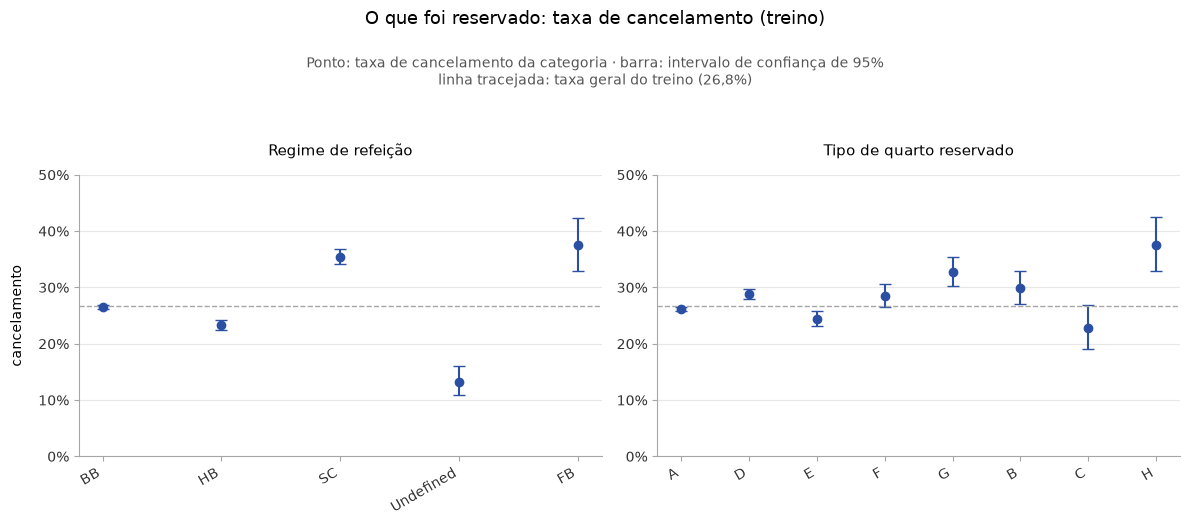

variavel,nivel,n,taxa,ic_inf,ic_sup
meal,BB,52719,0.2651,0.2614,0.2689
meal,FB,408,0.3750,0.3294,0.4229
meal,HB,8311,0.2328,0.2239,0.2420
meal,SC,5375,0.3548,0.3421,0.3677
meal,Undefined,642,0.1324,0.1084,0.1608
reserved_room_type,A,47631,0.2613,0.2574,0.2652
reserved_room_type,B,897,0.2988,0.2697,0.3295
reserved_room_type,C,443,0.2280,0.1914,0.2693
reserved_room_type,D,11353,0.2882,0.2799,0.2966
reserved_room_type,E,3717,0.2446,0.2310,0.2586


In [27]:
figura_categorias('O que foi reservado', ['meal', 'reserved_room_type', 'is_repeated_guest'])

**Leitura.**

- **Tipo de quarto:** taxas de 22,8% a 37,6%, sem ordem, e o código não significa nada para o público (V de 0,039). **Sai.**
- **Hóspede que volta:** 20,1% contra 27,0% (V de 0,027). Parecido com "já veio × nunca veio" (seção 3.4); a redundância é conferida na seção 4.
- **`meal`:** investigado abaixo.

#### Regime × hotel: reservas

Quantas reservas de cada regime há em cada hotel.

In [28]:
# meal: Undefined e SC são a mesma coisa? Onde cada um aparece
pd.crosstab(treino['meal'], treino['hotel'], margins=True, margins_name='total')

meal,City Hotel,Resort Hotel,total
BB,33479,19240,52719
FB,41,367,408
HB,3582,4729,8311
SC,5335,40,5375
Undefined,0,642,642
total,42437,25018,67455


**Leitura.**

- **Cada hotel registra "sem refeição" de um jeito.** Undefined só aparece no resort (642 reservas, nenhuma no urbano); SC aparece quase só no urbano (5.335, contra 40 no resort).

#### Regime × hotel: taxa

Para ver se SC e Undefined se comportam igual dentro do mesmo hotel.

In [29]:
# taxa de cancelamento de cada regime, em cada hotel
taxa_por_nivel(treino, ['hotel', 'meal'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

hotel,meal,n,taxa,ic_inf,ic_sup
City Hotel,BB,33479,0.2868,0.2820,0.2917
City Hotel,FB,41,0.8537,0.7156,0.9312
City Hotel,HB,3582,0.2259,0.2125,0.2398
City Hotel,SC,5335,0.3573,0.3445,0.3702
Resort Hotel,BB,19240,0.2273,0.2215,0.2333
Resort Hotel,FB,367,0.3215,0.2758,0.3709
Resort Hotel,HB,4729,0.2381,0.2262,0.2505
Resort Hotel,SC,40,0.0250,0.0044,0.1288
Resort Hotel,Undefined,642,0.1324,0.1084,0.1608


**Leitura.**

- **E os dois vão em sentidos opostos.** No urbano, SC cancela 35,7%, contra 28,7% do café da manhã (BB). No resort, Undefined cancela 13,2%, contra 22,7% do BB. Juntar SC e Undefined em "sem refeição" mistura um efeito para cima com um para baixo.
- **Pensão completa (FB):** 85,4% no urbano, mas são só 41 reservas; 32,2% no resort (367). Meia pensão (HB) fica perto de 23% nos dois hotéis.
- **Proposta: `meal` vai para teste com quatro níveis**: BB (referência), com pensão (HB e FB), SC e Undefined. Undefined fica separado mesmo sendo pequeno (0,9% do treino), porque não se parece com nenhum outro nível. A variável é fraca (V de 0,072): se não melhorar o modelo, sai.

#### Group: de onde vem

Parcela de cada segmento dentro de cada tipo de cliente.

In [30]:
# customer_type = Group (344 reservas): de que segmentos vêm, e com quem se parece?
pd.crosstab(treino['customer_type'], treino['segmento'], normalize='index').round(2)

customer_type,Corporate,Direct,Groups,Offline TA/TO,Online TA,Outros
Contract,0.0100,0,0.0600,0.4100,0.5200,0
Group,0.0400,0.2300,0.0100,0.3800,0.3300,0.0100
Transient,0.0500,0.1500,0.0100,0.1400,0.6400,0.0100
Transient-Party,0.0700,0.0400,0.3800,0.3700,0.1300,0


**Leitura.**

- **Group (344 reservas, 12,8% de cancelamento) não se parece com nenhum outro tipo de cliente.** O mais próximo é contrato (22,5%). Vem de operadoras (38%), agência online (33%) e reservas diretas (23%): não é o mesmo que o segmento Groups.
- **O avulso ligado a outra reserva (Transient-Party) é 38% do segmento Groups**: o tipo de cliente repete parte do segmento.
- **Sem proposta por ora: a seção 4 decide.** Group tem poucas reservas (344, 0,5% do treino) e não se parece com nenhum outro nível. As possibilidades:
  - **juntar com contrato:** a taxa mais próxima (22,5%), mas ainda quase 10 pontos acima, e os intervalos não se tocam;
  - **juntar com o avulso ligado a outra reserva:** o conceito mais próximo (reservas ligadas a outras), mas com taxa mais longe (24,2%);
  - **deixar separado**, como Undefined em `meal`: coerente com o critério de lá, mas o efeito sai instável com 344 reservas;
  - **tirar `customer_type` do modelo:** a variável é fraca (V de 0,049) e repete parte do segmento. Se a seção 4 mostrar que ela não acrescenta nada ao segmento, a questão do Group desaparece.

#### Mês de chegada

Para ver se o padrão de um ano se repete no outro.

In [31]:
# mês de chegada: o padrão se repete nos dois anos do treino?
taxa_mes = treino.pivot_table(index='arrival_date_month', columns='arrival_date_year', values='is_canceled', aggfunc='mean')
reservas_mes = treino.pivot_table(index='arrival_date_month', columns='arrival_date_year', values='is_canceled', aggfunc='size')
por_mes_ano = pd.concat([taxa_mes.add_prefix('taxa '), reservas_mes.add_prefix('reservas ').astype('Int64')], axis=1)
por_mes_ano.reindex(meses).rename_axis('mes').round(4)

mes,taxa 2015,taxa 2016,reservas 2015,reservas 2016
January,,0.1760,,2023
February,,0.2475,,3354
March,,0.2297,,4192
April,,0.2609,,4453
May,,0.2607,,4683
June,,0.2618,,4285
July,0.4077,0.2864,2524,4256
August,0.3092,0.3287,3279,4771
September,0.2286,0.2749,3894,4624
October,0.1717,0.3246,3833,5363


**Leitura.**

- **O padrão por mês não se repete nos dois anos.** Julho cancelou 40,8% em 2015 e 28,6% em 2016; outubro, 17,2% e 32,5%; dezembro, 20,4% e 32,6%. Com 12 meses como categorias, o modelo aprenderia oscilações de um ano só.
- **Só julho e agosto ficam acima nos dois anos:** 35,2% em 2015 e 30,9% em 2016. Os outros meses mudam de nível de um ano para o outro.

#### Temporadas candidatas

Taxa de julho e agosto, de abril a junho e de setembro a março, em cada ano do treino.

In [32]:
# três temporadas candidatas (jul–ago, abr–jun, set–mar), em cada ano do treino
temporada = treino['arrival_date_month'].map({'July': 'jul–ago', 'August': 'jul–ago',
                                              'April': 'abr–jun', 'May': 'abr–jun', 'June': 'abr–jun'}).fillna('set–mar')
taxa_por_nivel(treino.assign(temporada=temporada), ['temporada', 'arrival_date_year'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

temporada,arrival_date_year,n,taxa,ic_inf,ic_sup
abr–jun,2016,13421,0.2612,0.2538,0.2687
jul–ago,2015,5803,0.3521,0.3399,0.3644
jul–ago,2016,9027,0.3087,0.2993,0.3184
set–mar,2015,12342,0.1973,0.1904,0.2044
set–mar,2016,26862,0.2712,0.2660,0.2766


**Leitura.**

- **Abril a junho não se separa de setembro a março.** Em 2016, o único ano com os dois períodos, cancelam 26,1% e 27,1%, com intervalos que se tocam. As três temporadas candidatas viram, na prática, duas.
- **Proposta: alta temporada (julho e agosto) × resto do ano.** A diferença de 2015 para 2016 em setembro a março (19,7% para 27,1%) é a mesma tendência de alta vista no notebook 01, seção 3, e não um efeito da época do ano.

#### Agência × segmento

Taxa das reservas com e sem agência em cada segmento.

In [33]:
# agência e empresa: o vazio diz algo além do segmento?
taxa_por_nivel(treino, ['segmento', 'tem_agencia'])[['n', 'taxa']].round(4)

segmento,tem_agencia,n,taxa
Corporate,False,2982,0.1261
Corporate,True,549,0.1658
Direct,False,4128,0.1281
Direct,True,3720,0.1815
Groups,False,1520,0.2316
Groups,True,5881,0.3387
Offline TA/TO,False,148,0.2568
Offline TA/TO,True,14397,0.1734
Online TA,False,222,0.0721
Online TA,True,33274,0.3427


**Leitura.**

- **`tem_agencia` repete o segmento.** Na agência online e na operadora, quase todas as reservas têm agência; as sem agência são poucas (222 e 148). Onde há volume nos dois lados (direto, corporativo e grupos), ter agência soma de 4 a 11 pontos, mas o segmento já separa a maior parte. **Sai.**

#### Empresa × segmento

Taxa das reservas com e sem empresa em cada segmento.

In [34]:
taxa_por_nivel(treino, ['segmento', 'tem_empresa'])[['n', 'taxa']].round(4)

segmento,tem_empresa,n,taxa
Corporate,False,644,0.1553
Corporate,True,2887,0.1271
Direct,False,7720,0.1541
Direct,True,128,0.1094
Groups,False,6787,0.3411
Groups,True,614,0.0472
Offline TA/TO,False,14517,0.1745
Offline TA/TO,True,28,0.0714
Online TA,False,33427,0.3416
Online TA,True,69,0.0435


**Leitura.**

- **`tem_empresa` separa dentro do segmento.** Nos grupos, a reserva paga por empresa cancela 4,7% (614 reservas), contra 34,1% sem empresa. No corporativo, a diferença é pequena (12,7% contra 15,5%). **Proposta: testar "paga por empresa" como binária.** A empresa é conhecida na reserva, e a leitura para o negócio é direta.

#### As maiores agências

Taxa de cancelamento das 8 agências com mais reservas, em cada segmento.

In [35]:
# as maiores agências: o código separa reservas de risco diferente?
maiores = treino['agent'].value_counts().head(8).index
print('Agências no treino:', treino['agent'].nunique(),
      f"| as 8 maiores somam {treino['agent'].isin(maiores).mean():.1%} das reservas")
(taxa_por_nivel(treino[treino['agent'].isin(maiores)], ['agent', 'segmento'])[['n', 'taxa']]
     .query('n >= 100').round(4))

Agências no treino: 275 | as 8 maiores somam 58.3% das reservas


agent,segmento,n,taxa
1,Groups,3072,0.3906
6,Offline TA/TO,1945,0.1409
7,Online TA,2110,0.1393
9,Online TA,18611,0.3868
14,Direct,1959,0.1960
28,Offline TA/TO,1108,0.0460
240,Online TA,8805,0.3621
250,Direct,1675,0.1648


**Leitura.**

- **O código da agência separa reservas do mesmo segmento.** Na agência online, a agência 9 cancela 38,7% e a 7, 13,9%; na operadora, a 6 cancela 14,1% e a 28, 4,6%. Mas são 275 códigos anônimos, e as 8 maiores somam 58,3% das reservas. **Sai do modelo:** dummies por código não se explicam para a diretoria. **Próximo passo para o negócio:** com o nome real das agências, a taxa por agência vira uma lista de parceiros a acompanhar.

### 3.6 Treino × teste: a relação se mantém em 2017?

A seção 2.3 mostrou que 2017 tem diárias mais altas e mais reservas da agência online e com antecedência longa. Duas perguntas ficaram abertas:

1. a diária se relaciona com o cancelamento do mesmo jeito nos dois períodos?
2. quanto da alta de 2017 (de 26,6% para 31,8%) vem da mudança no perfil das reservas, e quanto de um cancelamento maior dentro de cada perfil?

#### Diária

Taxa de cancelamento por faixa de diária, com os decis do treino aplicados aos dois períodos.

limites,n treino,taxa treino,ic_inf treino,ic_sup treino,n teste,taxa teste,ic_inf teste,ic_sup teste
"(-inf, 48.0]",7140,0.1807,0.1719,0.1898,2669,0.2019,0.1872,0.2176
"(48.0, 62.538]",6351,0.2582,0.2476,0.2691,1770,0.2249,0.2060,0.2449
"(62.538, 72.25]",6929,0.2472,0.2372,0.2575,2098,0.1840,0.1680,0.2011
"(72.25, 80.75]",6583,0.2801,0.2694,0.2911,3029,0.2776,0.2620,0.2939
"(80.75, 90.0]",6776,0.2273,0.2175,0.2374,3004,0.3236,0.3071,0.3405
"(90.0, 100.0]",6724,0.2720,0.2615,0.2828,3356,0.2914,0.2763,0.3070
"(100.0, 113.6]",6725,0.2906,0.2798,0.3015,3655,0.3220,0.3071,0.3374
"(113.6, 129.6]",6747,0.3031,0.2922,0.3142,4538,0.3352,0.3216,0.3490
"(129.6, 157.0]",6760,0.3105,0.2996,0.3216,5268,0.3808,0.3678,0.3940
"(157.0, inf]",6720,0.3128,0.3018,0.3240,6969,0.3972,0.3858,0.4087


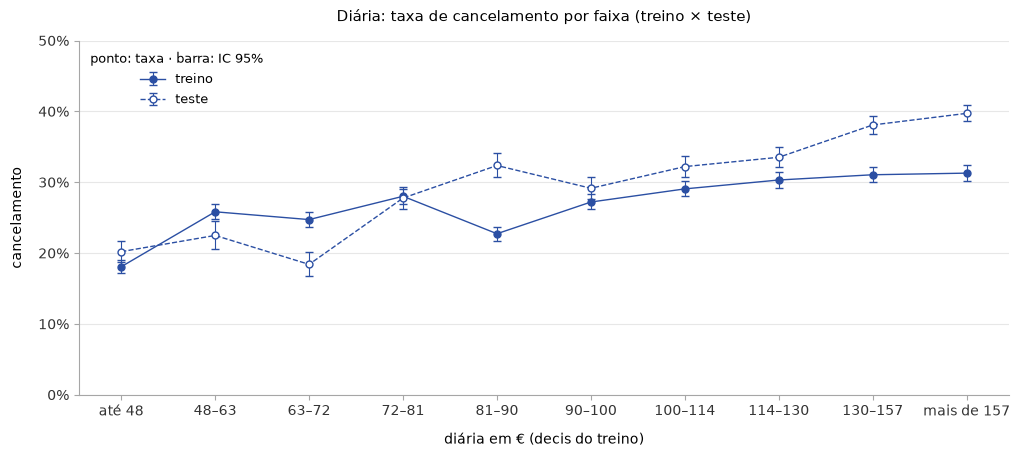

In [36]:
teste = teste.assign(
    segmento=teste['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}))

from matplotlib.ticker import PercentFormatter

# diária: decis do treino aplicados aos dois períodos (o corte é o mesmo, o preço é que muda)
cortes_adr = treino['adr'].quantile(np.linspace(0, 1, 11)).to_numpy().copy()
cortes_adr[0], cortes_adr[-1] = -np.inf, np.inf
por_decil = pd.concat([
    taxa_por_nivel(dados.assign(decil_adr=pd.cut(dados['adr'], cortes_adr)), 'decil_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']]
    .add_suffix(f' {periodo}')
    for periodo, dados in [('treino', treino), ('teste', teste)]
], axis=1).rename_axis('limites')
display(por_decil.round(4))

fig, ax = plt.subplots(figsize=(12, 4.6))
posicoes = np.arange(len(por_decil))
for periodo, estilo in [('treino', dict(marker='o', linestyle='-')), ('teste', dict(marker='o', linestyle='--', markerfacecolor='white'))]:
    taxa = por_decil[f'taxa {periodo}']
    erro = [taxa - por_decil[f'ic_inf {periodo}'], por_decil[f'ic_sup {periodo}'] - taxa]
    ax.errorbar(posicoes, taxa, yerr=erro, capsize=3, color=CORES['principal'], label=periodo,
                linewidth=1, elinewidth=0.8, markersize=5, **estilo)
rotulos = [f'{i.left:.0f}–{i.right:.0f}' for i in por_decil.index]
rotulos[0], rotulos[-1] = f'até {por_decil.index[0].right:.0f}', f'mais de {por_decil.index[-1].left:.0f}'
ax.set_xticks(posicoes, rotulos)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('diária em € (decis do treino)')
ax.set_ylabel('cancelamento')
ax.set_title('Diária: taxa de cancelamento por faixa (treino × teste)')
ax.legend(frameon=False, title='ponto: taxa · barra: IC 95%', title_fontsize=9, fontsize=9)
plt.show()

**Leitura.**

- **A relação da diária com o cancelamento muda em 2017.** Nas duas faixas mais caras do treino (acima de 130), o teste cancela 38,1% e 39,7%, contra 31,1% e 31,3% no treino. No meio da escala, as faixas sobem e descem sem padrão: de 63 a 72, 18,4% no teste contra 24,7%; de 81 a 90, 32,4% contra 22,7%.

#### Preço

Diária mediana em cada hotel, no treino e no teste.

In [37]:
# preço: a mediana da diária sobe nos dois hotéis
pd.concat({'treino': treino.groupby('hotel')['adr'].median(), 'teste': teste.groupby('hotel')['adr'].median()}, axis=1)

hotel,treino,teste
City Hotel,96.2000,114.4000
Resort Hotel,72.3000,88.2000


**Leitura.**

- **Parte disso é preço.** A diária mediana sobe de 96,2 para 114,4 no hotel urbano e de 72,3 para 88,2 no resort. Com as faixas fixas do treino, uma mesma faixa em euros junta reservas diferentes em cada ano: a faixa acima de 157 tem 6.720 reservas no treino e 6.969 no teste, que tem pouco mais da metade das reservas.
- **Consequência:** a diária em euros não serve como está. A seção 4 confere se ela acrescenta algo depois de controlar segmento e antecedência, que também mudam em 2017. Se não acrescentar, sai.

#### Perfil × comportamento

A taxa do treino em cada grupo de reservas (hotel × segmento × faixa de antecedência × temporada), aplicada ao perfil de 2017: quanto seria a taxa de 2017 se só o perfil das reservas tivesse mudado.

In [38]:
# perfil × comportamento: a taxa do treino em cada grupo de reservas, com o perfil de 2017
grupos_perfil = ['hotel', 'segmento', 'faixa_lead', 'temporada']
def com_perfil(dados):
    return dados.assign(
        faixa_lead=pd.cut(dados['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                          labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180']),
        temporada=np.where(dados['arrival_date_month'].isin(['July', 'August']), 'jul–ago', 'resto'))

taxa_grupo_treino = com_perfil(treino).groupby(grupos_perfil, observed=True)['is_canceled'].mean()
perfil_teste = com_perfil(teste).groupby(grupos_perfil, observed=True).size()
taxa_aplicada = taxa_grupo_treino.reindex(perfil_teste.index)
cobertos = taxa_aplicada.notna()
esperada_2017 = (perfil_teste[cobertos] * taxa_aplicada[cobertos]).sum() / perfil_teste[cobertos].sum()

alta = teste['is_canceled'].mean() - treino['is_canceled'].mean()
print(f"Parte da alta explicada só pelo perfil: {(esperada_2017 - treino['is_canceled'].mean()) / alta:.0%}")
print(f"Reservas de 2017 em grupos que existem no treino: {perfil_teste[cobertos].sum() / perfil_teste.sum():.1%}")
pd.Series({
    'treino (taxa real)': treino['is_canceled'].mean(),
    '2017 com as taxas do treino (só o perfil muda)': esperada_2017,
    '2017 (taxa real)': teste['is_canceled'].mean(),
}).to_frame('cancelamento').rename_axis('cenario').round(4)

Parte da alta explicada só pelo perfil: 70%
Reservas de 2017 em grupos que existem no treino: 100.0%


cenario,cancelamento
treino (taxa real),0.2677
2017 com as taxas do treino (só o perfil muda),0.3031
2017 (taxa real),0.3187


**Leitura.**

- **Cerca de 70% da alta de 2017 vem da mudança no perfil das reservas.** Aplicando as taxas do treino de cada grupo (hotel × segmento × faixa de antecedência × temporada) ao perfil de 2017, a taxa esperada seria 30,3%. A real foi 31,9%, e o treino tinha 26,8%: o perfil explica 70% dos 5,1 pontos de alta. Todas as reservas de 2017 caem em grupos que existem no treino.
- **O resto, cerca de 1,6 ponto, é cancelamento maior dentro do mesmo perfil.** É a parte que o modelo não capta e que aparece na calibração.

#### Segmento

Parcela e taxa de cada segmento, no treino e no teste.

In [39]:
# onde a taxa mudou dentro do perfil: segmento e antecedência, treino × teste
def taxa_e_peso(variavel, dados_treino, dados_teste):
    return pd.DataFrame({
        'pct_treino': dados_treino[variavel].value_counts(normalize=True),
        'pct_teste': dados_teste[variavel].value_counts(normalize=True),
        'taxa_treino': dados_treino.groupby(variavel, observed=True)['is_canceled'].mean(),
        'taxa_teste': dados_teste.groupby(variavel, observed=True)['is_canceled'].mean(),
    })

taxa_e_peso('segmento', treino, teste).sort_values('pct_teste', ascending=False).round(4)

segmento,pct_treino,pct_teste,taxa_treino,taxa_teste
Online TA,0.4966,0.6205,0.3409,0.4092
Direct,0.1163,0.1258,0.1534,0.1545
Offline TA/TO,0.2156,0.1236,0.1743,0.1693
Groups,0.1097,0.0840,0.3167,0.2049
Corporate,0.0523,0.0375,0.1323,0.1535
Outros,0.0094,0.0086,0.1356,0.1667


**Leitura.**

- **A agência online explica a maior parte da mudança.** Passa de 49,7% para 62,0% das reservas, e a taxa dela sobe de 34,1% para 40,9%. Nos grupos, a taxa cai de 31,7% para 20,5%; nos outros segmentos, quase não muda.

#### Antecedência

Parcela e taxa de cada faixa de antecedência, no treino e no teste.

In [40]:
taxa_e_peso('faixa_lead', com_perfil(treino), com_perfil(teste)).round(4)

faixa_lead,pct_treino,pct_teste,taxa_treino,taxa_teste
até 7,0.1993,0.1560,0.0966,0.0823
8–30,0.1805,0.1691,0.2496,0.2856
31–90,0.2764,0.2304,0.3088,0.3550
91–180,0.1948,0.2493,0.3346,0.3707
mais de 180,0.1489,0.1952,0.3546,0.4269


**Leitura.**

- **No total, a taxa sobe em todas as faixas de antecedência a partir de 8 dias** (de 3,6 a 7,2 pontos) e cai um pouco nas reservas de até 7 dias (de 9,7% para 8,2%).

#### Agência online

Parcela e taxa de cada faixa de antecedência, no treino e no teste.

In [41]:
# só a agência online
online_treino = com_perfil(treino).query("segmento == 'Online TA'")
online_teste = com_perfil(teste).query("segmento == 'Online TA'")
taxa_e_peso('faixa_lead', online_treino, online_teste).round(4)

faixa_lead,pct_treino,pct_teste,taxa_treino,taxa_teste
até 7,0.1696,0.1087,0.0965,0.0857
8–30,0.2045,0.1776,0.3114,0.3387
31–90,0.3162,0.2572,0.3841,0.4222
91–180,0.2147,0.2664,0.4283,0.4671
mais de 180,0.0950,0.1902,0.4998,0.5613


**Leitura.**

- **Dentro da agência online, a antecedência também se alonga.** As reservas com mais de 180 dias passam de 9,5% para 19,0%. E a taxa sobe em todas as faixas a partir de 8 dias, de 2,7 a 6,2 pontos: com mais de 180 dias, de 50,0% para 56,1%.
- **O que isso muda:**
  - com segmento e antecedência no modelo, a maior parte da alta de 2017 é captada. A previsão para 2017 deve sair baixa em cerca de 1,6 ponto, e não em 5;
  - a ordem das reservas quase se mantém: na antecedência e na agência online, quem cancelava mais no treino continua cancelando mais em 2017. A exceção são os grupos, que caem de 31,7% para 20,5% e passam a ficar abaixo da média;
  - a interação agência online × antecedência fica para a seção 4: dentro da agência online, a antecedência separa muito mais (de 8,6% a 56,1% no teste) do que na base toda.

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa com os notebooks do grupo está em `comparacao_decisoes.md`. Os pontos de escopo e limpeza estão no fim do `01_exploratoria.ipynb`.*

| # | Decisão | Proposta deste notebook | Evidência | Notebooks do grupo |
| --- | --- | --- | --- | --- |
| 1 | **Faixas de antecedência** | Cortes da árvore de decisão (ganho de informação): 0, 1–8, 9–25, 26–257, 258–315 e mais de 315 dias, com 26–257 como referência. A seção 4 confere se o corte de 315 continua com o segmento no modelo | 3.1 | `TODO.md` e dicionário: até 7, 8–30, 31–90, 91–180 e mais de 180 dias (261,5 pontos de BIC atrás da melhor opção) |
| 2 | **Faixas de noites** | Cortes da árvore de decisão: 1, 2–3 e 4 ou mais noites, com 2–3 como referência. As reservas com zero noites saíram da base (notebook 01, seção 4.4) | 3.2 | Dicionário: até 1 (com as zero noites), 2–3, 4–7 e mais de 7. Notebook 03: zero noites numa faixa própria |
| 3 | **`previous_cancellations`** | Sai: 1 cancelamento anterior cancela 92,5% no treino e 17,6% no teste | 3.4 | Testar: já cancelou × nunca cancelou |
| 4 | **Crianças e bebês** | "Com criança" só com `children`; `babies` sai (com bebê cancela 20,8%, contra 26,8% sem) | 3.4 | `com_crianca` soma crianças e bebês |
| 5 | **`meal`** | Testar com quatro níveis: BB (referência), com pensão (HB e FB), SC e Undefined | 3.5 | Sem refeição (SC e Undefined) × com refeição |
| 6 | **Temporadas** | Duas: julho e agosto × resto do ano | 3.5 | Três: jul–ago, abr–jun e set–mar |
| 7 | **`customer_type`** | A decidir na seção 4: entra ou sai e, se entrar, o destino do nível Group | 3.5 | Entra |
| 8 | **`company`** | Testar a binária "paga por empresa" | 3.5 | Sai |
| 9 | **`adr`** | Em euros, não serve como está; a seção 4 decide se entra | 3.6 | Entra como número |
| 10 | **Leitura da alta de 2017** | 70% vem da mudança no perfil das reservas | 3.6 | Notebook 03: "sobretudo comportamento". Conferir se a diferença vem dos grupos usados em cada decomposição |